# CDSD Bloc 3 — Conversion Rate Prediction

Copyright © 2026 · voir le fichier LICENSE du dépôt

**Projet :** prédire si un visiteur va s'abonner à la newsletter *Data Science Weekly* à partir de données structurées.

**Objectif métier :** identifier les visiteurs à forte probabilité de conversion, comprendre les facteurs associés à la conversion et proposer des leviers d'action.

**Objectif certification Bloc 3 :** couvrir explicitement les compétences attendues :

1. construire un pipeline de traitement de données structurées ;
2. entraîner et évaluer des modèles supervisés ;
3. interpréter les facteurs prédictifs et formuler des recommandations métier ;
4. ajouter une segmentation non supervisée pour couvrir la compétence clustering / réduction de dimension.

> **Positionnement :** ce notebook est volontairement très commenté. Les commentaires expliquent non seulement ce qui est fait, mais aussi pourquoi ces choix sont préférés à des alternatives plus faibles ou moins adaptées au contexte.

---

## Documentation vivante de ce notebook

Cinq rubriques, relues à chaque modification du code : elles disent ce qui a été décidé, où cela vit, comment cela marche et ce qui le prouve.

## CHOIX

- Retenu : un notebook explicatif (le raisonnement reste dans les cellules Markdown) adossé à un module `conversion_bloc3.py`, placé à côté de lui, qui contient les fonctions de calcul. Ces fonctions sont testées sans exécuter le notebook (`tests/test_conversion_bloc3.py:246`), et un test d'intégration exécute le notebook entier et vérifie ses chiffres clés (`tests/test_notebook_conversion.py:97`).
- Retenu : ce que le jury peut vouloir modifier en direct reste dans les cellules, pas dans le module : `RANDOM_STATE` (cellule 3), `num_cols` et `cat_cols` (cellule 19), la liste des modèles comparés (cellule 27), `best_threshold` (cellule 31) et `k` des clusters (cellules 49 et 50).
- Retenu pour le modèle : F1-score (métrique du challenge) plutôt que l'exactitude, découpage stratifié 80/20, régression logistique régularisée comparée à une référence naïve, une forêt aléatoire et un essai de pondération des classes, seuil de décision optimisé sur la validation, validation croisée stratifiée à 5 plis.
- Écartés, avec la raison : l'exactitude (un modèle qui répond toujours « non converti » aurait 97 % de bonnes réponses), le seuil 0,50 par défaut (arbitraire), `LabelEncoder` (ordre artificiel entre pays), la suppression des doublons (deux visiteurs peuvent avoir le même profil), un modèle complexe non interprétable. Le détail est dans les sections 0, 4 et 6.
- Écarté pour la conformité : garder les fonctions dans les cellules sans test.

## OÙ

- Rôle : livrable du bloc 3 CDSD (RNCP35288) sur la prédiction de conversion à la newsletter. Il n'a pas d'appelant : c'est un document final, relu et exécuté de haut en bas.
- Il appelle `conversion_bloc3.py` (fonctions de calcul) et lit `conversion_data_train.csv` et `conversion_data_test.csv`, placés à côté de lui. Il écrit les figures et le résumé dans `outputs_bloc3_conversion_commente/` (par exemple `outputs_bloc3_conversion_commente/summary_results.json:2`) et les deux fichiers de prédictions à côté du notebook.
- Dépendances : numpy, pandas, scikit-learn, matplotlib et IPython, aux versions épinglées dans `requirements.txt` (celles que la cellule 3 affiche). Les outils de test sont dans `requirements-dev.txt`.

## COMMENT

- Les sections se lisent dans l'ordre : chargement et audit (2), exploration (3), prétraitement (4), seuil et évaluation (5), modèles (6), meilleur modèle (7), validation croisée (7 bis), variante sans `total_pages_visited` (8), coefficients et recommandations (9), fichier de soumission (10), segmentation des visiteurs (11), RGPD (11 bis), synthèse (13), angles morts (14).
- Reproductibilité : `RANDOM_STATE = 42` fixe tous les tirages ; la cellule 3 affiche les versions des bibliothèques.
- Tests : `python -m pytest tests -W error::DeprecationWarning -W error::PendingDeprecationWarning`. Les tests du module sont rapides ; les tests du notebook (`-m notebook`) l'exécutent, environ une minute pour l'ensemble. Un test relance aussi les cellules 0 à 31 avec un autre seuil (`tests/test_notebook_conversion.py:137`) et avec une variable retirée du modèle.

## POURQUOI

- Référentiel : RNCP35288, bloc 3, https://www.francecompetences.fr/recherche/rncp/35288/ ; documentation scikit-learn de `Pipeline`, `LogisticRegression`, `StratifiedKFold` et `KMeans`.
- Les chiffres cités dans le texte sont calculés par le notebook et écrits dans `outputs_bloc3_conversion_commente/summary_results.json:2` ; aucun n'est saisi à la main.
- Le F1-score comme métrique et la soumission d'un fichier `converted` viennent de l'énoncé du challenge, fourni par l'organisme de formation et non redistribué ici.
- Les seuils de lecture des diagnostics (0,02 sur l'écart apprentissage − validation et sur la dispersion entre plis) sont des conventions de lecture du notebook : source : inconnue, sans référence externe.

## JOURNALISATION

- Le notebook ne journalise pas dans un fichier : ses affichages font le journal. Cellule 3 : versions de Python et des bibliothèques. Cellules 6 à 8 : dimensions, schéma, valeurs manquantes et doublons. Cellule 27 : tableau des modèles comparés. Cellule 36 : diagnostic de validation croisée. Cellule 45 : fichiers de prédictions écrits. Cellule 58 : résumé exporté en JSON.
- Les données décrivent des visiteurs (pays, âge, pages vues) : ce sont des données personnelles non anonymes (section 11 bis). Les sorties écrites sont des probabilités par ligne et des agrégats ; elles ne doivent pas être diffusées hors de l'équipe concernée.
- Le module `conversion_bloc3.py` ne journalise rien ; ses fonctions sont pures.


## 0. Stratégie de réponse au sujet

Le challenge impose une métrique : **F1-score**. Le choix du pipeline, du modèle et du seuil de décision doit donc être aligné avec cette métrique, et pas avec l'accuracy.

La cible est rare : environ 3 % des visiteurs convertissent. Un modèle naïf qui prédit toujours « non converti » aurait une accuracy élevée, mais il serait inutile pour le métier. C'est la raison principale pour laquelle le F1-score, la précision, le rappel, la **PR-AUC** (aire sous la courbe précision-rappel, adaptée aux classes rares) et la matrice de confusion sont mis en avant.

### Ce qui a été renforcé pour éviter les zones d'ombre

- Les cellules de code sont commentées par intention : chaque import, transformation, modèle, métrique et export a une justification.
- Les alternatives écartées sont nommées : accuracy seule, split non stratifié, label encoding, seuil 0,50 par défaut, modèle complexe non interprétable, suppression automatique des doublons. Le déséquilibre de classes n'est pas traité par la seule métrique : un essai de **pondération des classes** (`class_weight="balanced"`) est comparé.
- Les limites sont explicites : corrélation ≠ causalité, **causalité inverse** possible pour `total_pages_visited`, disponibilité temporelle de cette variable, dérive des données, calibration, suivi et A/B test.
- Une matrice finale recense les angles morts méthodologiques et la réponse apportée à chacun.

## 1. Imports, configuration et reproductibilité

In [1]:
# ============================================================
# 1. Imports, configuration générale et chemins de fichiers
# ============================================================
# Tous les imports sont regroupés ici, en tête du notebook (convention PEP 8 :
# bibliothèque standard, puis bibliothèques tierces). On voit ainsi d'un coup d'œil de
# quoi dépend le projet.

# --- Bibliothèque standard ---
# json : export du résumé des résultats (réutilisable dans un rapport) ;
# os : réglage des threads avant le chargement de NumPy ;
# platform : version de Python affichée plus bas ;
# pathlib : chemins portables, plus lisibles que des chaînes de caractères brutes.
import json
import os
import platform
import sys
from pathlib import Path

# Limitation des threads de certaines bibliothèques numériques, posée AVANT le chargement
# de NumPy : l'exécution reste stable sur des machines limitées. Les résultats ne changent pas.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

# Le module conversion_bloc3.py (les fonctions de calcul, testées dans tests/) est à côté de ce
# notebook. Le noyau Jupyter ne démarre pas toujours dans ce dossier : on l'ajoute au chemin
# d'import AVANT de l'importer, en remontant depuis le dossier courant (comme trouver_racine).
sys.path.insert(
    0,
    str(
        next(
            (
                dossier
                for parent in (Path.cwd(), *Path.cwd().parents)
                for dossier in (parent, parent / "2_Conversion")
                if (dossier / "conversion_bloc3.py").exists()
            ),
            Path.cwd(),
        )
    ),
)

# --- Bibliothèques tierces ---
# NumPy (calcul vectorisé), pandas (données tabulaires), matplotlib (graphiques),
# IPython (version affichée plus bas ; l'affichage passe par afficher() du module).
# Les commentaires « type: ignore » disent à mypy que pandas et scikit-learn ne publient pas
# de types : ils ne changent rien à l'exécution.
import IPython
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # type: ignore[import-untyped]
import sklearn  # type: ignore[import-untyped]

# Modèles non supervisés : KMeans pour segmenter, PCA pour visualiser en 2D.
from sklearn.cluster import KMeans  # type: ignore[import-untyped]

# Prétraitement scikit-learn : les transformations sont intégrées dans un Pipeline pour
# éviter les fuites de données entre train et validation.
from sklearn.compose import ColumnTransformer  # type: ignore[import-untyped]
from sklearn.decomposition import PCA  # type: ignore[import-untyped]

# Modèles supervisés : référence naïve, modèle non linéaire, modèle linéaire interprétable.
from sklearn.dummy import DummyClassifier  # type: ignore[import-untyped]
from sklearn.ensemble import RandomForestClassifier  # type: ignore[import-untyped]
from sklearn.impute import SimpleImputer  # type: ignore[import-untyped]
from sklearn.linear_model import LogisticRegression  # type: ignore[import-untyped]

# Métriques : F1 est la métrique du challenge ; les autres servent à interpréter le
# compromis précision / rappel (average_precision_score = PR-AUC) et la capacité de
# classement du modèle (ROC-AUC). Davies-Bouldin et silhouette évaluent le clustering.
from sklearn.metrics import (  # type: ignore[import-untyped]
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    davies_bouldin_score,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    silhouette_score,
)

# train_test_split : découpage train/validation ; StratifiedKFold et cross_validate :
# validation croisée qui garde la proportion de convertis dans chaque pli.
from sklearn.model_selection import (  # type: ignore[import-untyped]
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline  # type: ignore[import-untyped]
from sklearn.preprocessing import StandardScaler  # type: ignore[import-untyped]

# --- Fonctions de calcul du projet (module testé, à côté du notebook) -------------
from conversion_bloc3 import (
    afficher,
    afficher_markdown,
    conversion_summary,
    evaluate_classifier,
    lecture_ecart_apprentissage,
    lecture_stabilite,
    make_model_pipeline,
    make_one_hot_encoder,
    optimize_threshold,
    resume_clusters,
    statut_visiteurs,
    trouver_racine,
)

# RANDOM_STATE rend les découpages et les modèles reproductibles.
# C'est important pour que l'on puisse relancer le notebook et retrouver les mêmes résultats.
RANDOM_STATE = 42

# Dossier du projet. Le noyau Jupyter ne démarre pas toujours dans le dossier du notebook
# (selon l'éditeur, le dossier de travail peut être le dossier parent, ou ailleurs). On
# cherche donc le dossier qui CONTIENT ce notebook, en remontant depuis le dossier courant ;
# à défaut, on garde le dossier courant.
NOM_NOTEBOOK = "Conversion_Rate_Bloc3_CDSD_v2.ipynb"

# Les deux CSV du challenge sont placés dans le même dossier que le notebook.
DATA_DIR = trouver_racine(NOM_NOTEBOOK, "2_Conversion")
TRAIN_PATH = DATA_DIR / "conversion_data_train.csv"
TEST_PATH = DATA_DIR / "conversion_data_test.csv"

# Dossier de sortie : les figures et fichiers de prédictions seront centralisés ici.
# Cela évite de disperser les artefacts du projet.
OUTPUT_DIR = DATA_DIR / "outputs_bloc3_conversion_commente"
OUTPUT_DIR.mkdir(exist_ok=True)

# Paramètres d'affichage pour rendre les tableaux plus lisibles.
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Polices un peu plus grandes que les valeurs par défaut de Matplotlib : les figures restent
# lisibles quand elles sont reprises, réduites, dans le support de présentation.
plt.rcParams.update(
    {
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 11,
    }
)

# Versions de l'environnement : à rapprocher du fichier requirements.txt.
print("Python        :", platform.python_version())
print("numpy         :", np.__version__)
print("pandas        :", pd.__version__)
print("scikit-learn  :", sklearn.__version__)
print("matplotlib    :", matplotlib.__version__)
print("IPython       :", IPython.__version__)
print("Dossier de données :", DATA_DIR.name)
print("Dossier de sortie  :", OUTPUT_DIR.name)

Python        : 3.12.14
numpy         : 2.5.4
pandas        : 3.0.6
scikit-learn  : 1.9.1
matplotlib    : 3.11.2
IPython       : 9.17.1
Dossier de données : 2_Conversion
Dossier de sortie  : outputs_bloc3_conversion_commente


**Pourquoi cette configuration ?**

- `random_state=42` garantit la reproductibilité des résultats.
- Les transformations sont intégrées dans des `Pipeline` scikit-learn pour empêcher une fuite de données : le scaler et le one-hot encoder sont appris uniquement sur le train dans chaque évaluation.
- `matplotlib` suffit pour les graphiques ; ajouter des dépendances externes n’apporterait pas de valeur pour la certification.

## 2. Chargement des données et audit qualité

In [2]:
# ============================================================
# 2. Chargement des fichiers CSV
# ============================================================

# read_csv est adapté car les données sont structurées et fournies au format tabulaire.
# On charge séparément le train labellisé et le test non labellisé, comme dans un challenge Kaggle.
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

# Vérification immédiate des dimensions :
# - train doit contenir les variables explicatives + la cible converted ;
# - test doit contenir les mêmes variables explicatives, sans la cible.
print("Train shape:", train.shape)
print("Test shape :", test.shape)

# Affichage des premières lignes pour vérifier le format réel des colonnes.
# Ce contrôle visuel évite de construire un pipeline sur une hypothèse incorrecte.
afficher(train.head())

Train shape: (284580, 6)
Test shape : (31620, 5)


In [3]:
# ============================================================
# 2.1 Contrôles de cohérence du schéma
# ============================================================

# On vérifie explicitement que la cible est bien dans le train.
# Sans cette colonne, il serait impossible d'entraîner un modèle supervisé.
assert "converted" in train.columns, "La colonne cible 'converted' est absente du fichier train."

# Le test ne doit pas contenir la cible : c'est le principe du challenge.
# Si elle était présente, on risquerait une fuite ou une évaluation non indépendante.
assert "converted" not in test.columns, "Le fichier test ne doit pas contenir la cible."

# Les colonnes explicatives du train doivent être exactement celles du test.
# Cette vérification sécurise l'étape de prédiction finale.
train_features = train.drop(columns="converted").columns.tolist()
test_features = test.columns.tolist()
assert train_features == test_features, (
    "Les colonnes explicatives train/test ne correspondent pas."
)

print("Schéma validé : mêmes variables explicatives dans train et test.")
print("Variables explicatives :", train_features)

Schéma validé : mêmes variables explicatives dans train et test.
Variables explicatives : ['country', 'age', 'new_user', 'source', 'total_pages_visited']


In [4]:
# ============================================================
# 2.2 Audit qualité : types, valeurs manquantes et doublons
# ============================================================

# Audit du train : type de chaque colonne, nombre de valeurs manquantes,
# proportion de valeurs manquantes.
audit_train = pd.DataFrame(
    {
        "dtype_train": train.dtypes.astype(str),
        "missing_train": train.isna().sum(),
        "missing_rate_train": train.isna().mean(),
    }
)

# Audit du test avec la même logique.
# On vérifie que le modèle ne recevra pas une structure différente en prédiction.
audit_test = pd.DataFrame(
    {
        "dtype_test": test.dtypes.astype(str),
        "missing_test": test.isna().sum(),
        "missing_rate_test": test.isna().mean(),
    }
)

print("Audit train")
afficher(audit_train)

print("Audit test")
afficher(audit_test)

# Les doublons ne sont pas automatiquement supprimés.
# Justification : deux visiteurs différents peuvent avoir le même profil agrégé
# si les variables disponibles sont peu nombreuses.
train_duplicates = train.duplicated().sum()
test_duplicates = test.duplicated().sum()
print(f"Doublons train : {train_duplicates:,}".replace(",", " "))
print(f"Doublons test  : {test_duplicates:,}".replace(",", " "))

Audit train


,dtype_train,missing_train,missing_rate_train
country,str,0,0.0
age,int64,0,0.0
new_user,int64,0,0.0
source,str,0,0.0
total_pages_visited,int64,0,0.0
converted,int64,0,0.0


Audit test


,dtype_test,missing_test,missing_rate_test
country,str,0,0.0
age,int64,0,0.0
new_user,int64,0,0.0
source,str,0,0.0
total_pages_visited,int64,0,0.0


Doublons train : 268 769
Doublons test  : 24 140


**Conclusion audit.** Les fichiers sont exploitables : pas de valeur manquante, types cohérents, mêmes variables explicatives dans `train` et `test`. Les doublons ne sont pas supprimés parce que le dataset décrit des profils agrégés : deux visiteurs distincts peuvent partager les mêmes valeurs sur seulement cinq variables.

**Pourquoi conserver des imputers dans le pipeline alors qu’il n’y a pas de valeurs manquantes ?** Parce qu’un pipeline de production doit être robuste. Si de futures données contiennent quelques valeurs manquantes, le modèle pourra continuer à fonctionner sans rupture technique.

## 3. EDA — compréhension métier de la cible et des variables

Distribution de la cible


,count,rate
converted,,
non_converti,275400,0.967742
converti,9180,0.032258


Taux de conversion global : 3.23%
Ratio non-convertis / convertis : 30.0:1


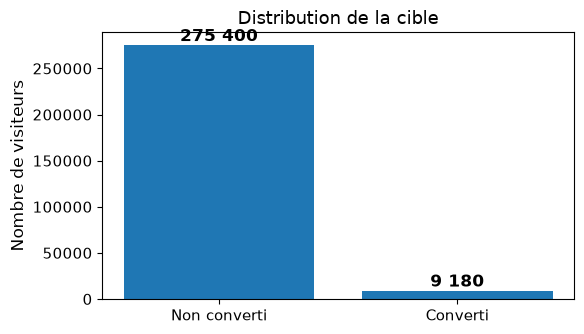

In [5]:
# ============================================================
# 3.1 Distribution de la cible
# ============================================================

# La distribution de la cible est le premier point à analyser : elle détermine
# le choix des métriques et explique pourquoi l'accuracy peut être trompeuse.
target_counts = train["converted"].value_counts().sort_index()
conversion_rate = train["converted"].mean()
imbalance_ratio = target_counts.loc[0] / target_counts.loc[1]

target_distribution = pd.DataFrame(
    {
        "count": target_counts,
        "rate": target_counts / len(train),
    }
).rename(index={0: "non_converti", 1: "converti"})

print("Distribution de la cible")
afficher(target_distribution)
print(f"Taux de conversion global : {conversion_rate:.2%}")
print(f"Ratio non-convertis / convertis : {imbalance_ratio:.1f}:1")

# Visualisation simple en barres : suffisante pour montrer le déséquilibre.
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(["Non converti", "Converti"], target_counts.values)
ax.set_title("Distribution de la cible")
ax.set_ylabel("Nombre de visiteurs")

# On annote les barres pour rendre le graphique lisible sans calcul mental.
for bar, value in zip(bars, target_counts.values, strict=True):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

fig.tight_layout()
plt.show()

# Export optionnel de la figure pour réutilisation dans le diaporama.
fig.savefig(OUTPUT_DIR / "target_distribution.png", dpi=160, bbox_inches="tight")

In [6]:
# ============================================================
# 3.2 Fonction de synthèse du taux de conversion par segment
# ============================================================


# conversion_summary(df, column) est dans conversion_bloc3.py (testée dans tests/) : volume et
# taux de conversion par modalité d'une variable, du plus fort taux au plus faible.
#
# Pourquoi une fonction ?
# - éviter de répéter le même groupby ;
# - garantir la même définition du taux de conversion partout ;
# - rendre le notebook plus facile à relire.


# On travaille sur une copie pour l'EDA afin de ne pas polluer le DataFrame train
# utilisé ensuite pour la modélisation.
eda = train.copy()

# Variables catégorielles ou binaires : le groupby donne directement les taux par groupe.
country_summary = conversion_summary(eda, "country")
source_summary = conversion_summary(eda, "source")
new_user_summary = conversion_summary(eda, "new_user").rename(
    index={0: "Returning user", 1: "New user"}
)

# Âge : variable numérique continue.
# Pour l'EDA uniquement, on crée des classes d'âge afin de faciliter la lecture métier.
# On ne donne pas ces classes au modèle final pour ne pas perdre l'information continue.
age_bins = [0, 24, 30, 36, 42, np.inf]
age_labels = ["≤24", "25–30", "31–36", "37–42", "43+"]
eda["age_bin"] = pd.cut(eda["age"], bins=age_bins, labels=age_labels)
age_summary = conversion_summary(eda, "age_bin").sort_index()

# Nombre de pages : signal d'engagement.
# Les bins servent à visualiser une relation non linéaire entre engagement et conversion.
pages_bins = [-0.1, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, np.inf]
pages_labels = ["0–1", "2", "3", "4", "5", "6", "7–8", "9–10", "11–12", "13–15", "16–20", "21+"]
eda["pages_bin"] = pd.cut(eda["total_pages_visited"], bins=pages_bins, labels=pages_labels)
pages_summary = conversion_summary(eda, "pages_bin").sort_index()

print("Taux de conversion par pays")
afficher(country_summary)
print("Taux de conversion par source")
afficher(source_summary)
print("Taux de conversion nouveau / retour")
afficher(new_user_summary)
print("Taux de conversion par classe d'âge")
afficher(age_summary)

Taux de conversion par pays


,count,conversion_rate
country,,
Germany,11693,0.062431
UK,43641,0.052497
US,160124,0.037908
China,69122,0.001288


Taux de conversion par source


,count,conversion_rate
source,,
Ads,80027,0.034801
Seo,139477,0.032873
Direct,65076,0.027814


Taux de conversion nouveau / retour


,count,conversion_rate
new_user,,
Returning user,89514,0.071933
New user,195066,0.014052


Taux de conversion par classe d'âge


,count,conversion_rate
age_bin,,
≤24,75155,0.055419
25–30,75988,0.034229
31–36,66761,0.022933
37–42,41446,0.015538
43+,25230,0.009473


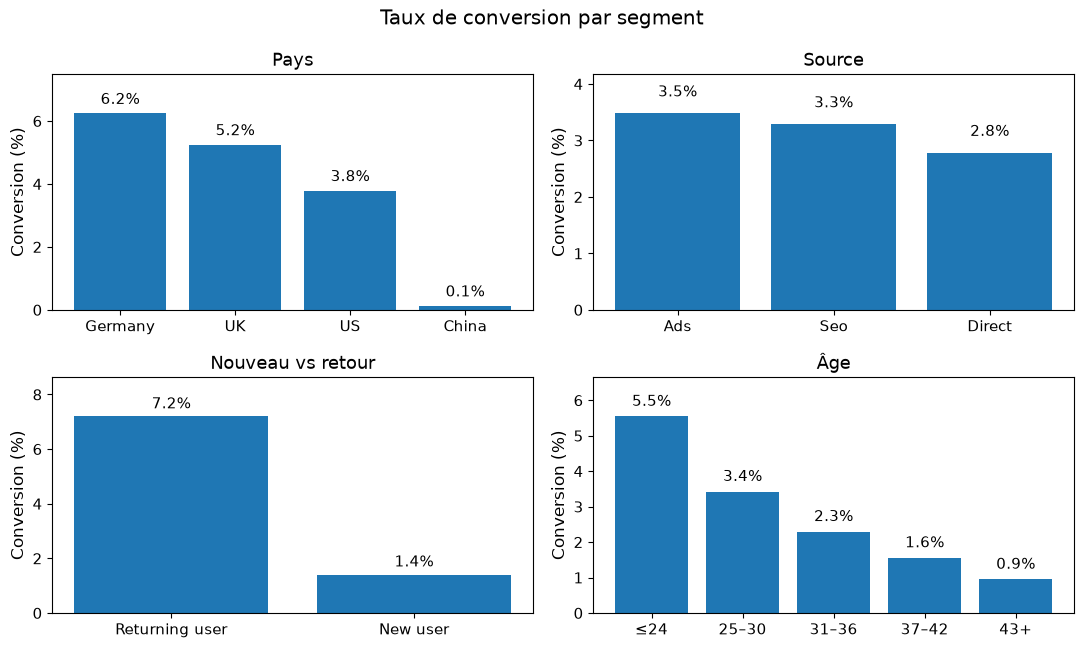

In [7]:
# ============================================================
# 3.3 Graphiques EDA par segments
# ============================================================

# On affiche quatre vues complémentaires dans une même figure pour synthétiser l'EDA.
# Ce graphique est utile dans la présentation : il montre les variables qui discriminent.
fig, axs = plt.subplots(2, 2, figsize=(11, 6.6))

plot_specs = [
    (country_summary, "Pays"),
    (source_summary, "Source"),
    (new_user_summary, "Nouveau vs retour"),
    (age_summary, "Âge"),
]

for ax, (summary, title) in zip(axs.flat, plot_specs, strict=True):
    # Pour les variables nominales, on trie par taux de conversion décroissant.
    # Pour l'âge, on conserve l'ordre naturel des classes.
    if title != "Âge":
        summary = summary.sort_values("conversion_rate", ascending=False)

    bars = ax.bar([str(index) for index in summary.index], summary["conversion_rate"] * 100)
    ax.set_title(title)
    ax.set_ylabel("Conversion (%)")
    ax.set_ylim(0, summary["conversion_rate"].max() * 100 * 1.2)

    # Les annotations de pourcentage rendent le graphique exploitable sans lire l'axe.
    for bar, value in zip(bars, summary["conversion_rate"] * 100, strict=True):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.3,
            f"{value:.1f}%",
            ha="center",
            fontsize=11,
        )

fig.suptitle("Taux de conversion par segment")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "conversion_rates_segments.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

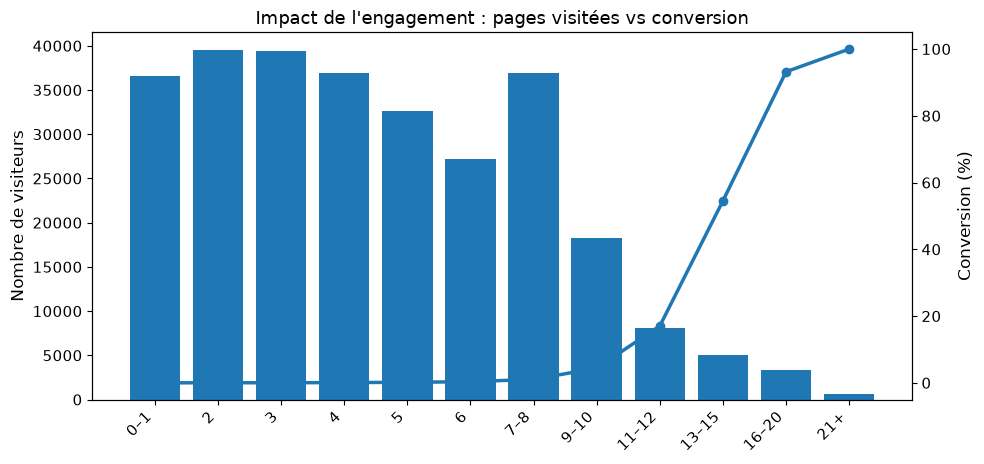

In [8]:
# ============================================================
# 3.4 Relation entre engagement et conversion
# ============================================================

# total_pages_visited est une variable métier centrale : elle approxime l'intention.
# On compare volume et conversion pour ne pas confondre un fort taux sur un micro-segment
# avec un segment réellement exploitable.
fig, ax1 = plt.subplots(figsize=(10, 4.8))
labels = [str(x) for x in pages_summary.index]
x = np.arange(len(labels))

# Axe gauche : volume de visiteurs par tranche de pages.
ax1.bar(x, pages_summary["count"], label="Volume")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=45, ha="right")
ax1.set_ylabel("Nombre de visiteurs")

# Axe droit : taux de conversion par tranche.
# Deux axes sont justifiés ici car volume et taux n'ont pas la même unité.
ax2 = ax1.twinx()
ax2.plot(x, pages_summary["conversion_rate"] * 100, marker="o", linewidth=2.5, label="Conversion")
ax2.set_ylabel("Conversion (%)")
ax2.grid(False)

ax1.set_title("Impact de l'engagement : pages visitées vs conversion")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pages_conversion_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

In [9]:
# ============================================================
# 3.5 Contrôles complémentaires : pages élevées, âges extrêmes, unicité des profils
# ============================================================
# Trois vérifications qui conditionnent l'interprétation de la suite.

# --- a) Conversion selon le nombre de pages : pourquoi total_pages_visited est un
#        INDICATEUR D'INTENTION et non un levier prouvé. Les tranches sont fines pour
#        montrer le plateau : au-delà d'un certain nombre de pages, presque tous convertissent.
print("Conversion par tranche de pages visitées :")
afficher(pages_summary)

tranches = pd.cut(
    train["total_pages_visited"], bins=[-1, 15, 20, np.inf], labels=["≤15", "16–20", "21+"]
)
resume_tranches = train.groupby(tranches, observed=True)["converted"].agg(
    visiteurs="size", taux_conversion="mean"
)
afficher(resume_tranches)
taux_16_20 = float(resume_tranches.loc["16–20", "taux_conversion"])
taux_21_plus = float(resume_tranches.loc["21+", "taux_conversion"])
n_21_plus = int(resume_tranches.loc["21+", "visiteurs"])

# --- b) Âges extrêmes : des valeurs non plausibles faussent-elles la modélisation ?
print("Distribution de l'âge (train) :")
afficher(train["age"].describe().to_frame().T)
ages_extremes = train[train["age"] > 90]
print(f"Lignes d'âge supérieur à 90 ans (train) : {len(ages_extremes)} sur {len(train)}")
afficher(ages_extremes)
print(f"Âge maximal dans le fichier test : {int(test['age'].max())} ans")

# --- c) Unicité des profils : ces données sont-elles anonymes ? (réutilisé en section 11 bis)
variables_explicatives = train.drop(columns="converted")
n_profils = len(variables_explicatives.drop_duplicates())
lignes_uniques = int((~variables_explicatives.duplicated(keep=False)).sum())
part_uniques = lignes_uniques / len(train)
print(
    f"Profils distincts (5 variables) : {n_profils:,} pour {len(train):,} lignes ; "
    f"lignes dont le profil est unique : {lignes_uniques:,} ({part_uniques:.2%})".replace(",", " ")
)

Conversion par tranche de pages visitées :


,count,conversion_rate
pages_bin,,
0–1,36637,0.000000
2,39546,0.000228
3,39465,0.000279
4,36918,0.000786
5,32654,0.001562
6,27198,0.003456
7–8,36880,0.010304
9–10,18284,0.044082
11–12,8079,0.170442


,visiteurs,taux_conversion
total_pages_visited,,
≤15,280659,0.019536
16–20,3295,0.932018
21+,626,1.000000


Distribution de l'âge (train) :


,count,mean,std,min,25%,50%,75%,max
age,284580.0,30.564203,8.266789,17.0,24.0,30.0,36.0,123.0


Lignes d'âge supérieur à 90 ans (train) : 2 sur 284580


Âge maximal dans le fichier test : 69 ans
Profils distincts (5 variables) : 13 942 pour 284 580 lignes ; lignes dont le profil est unique : 2 966 (1.04%)


**Constats de l'EDA.**

- Le taux de conversion global est faible : la classe positive est rare.
- `total_pages_visited` est un **indicateur d'intention** très discriminant : la conversion monte avec le nombre de pages vues et atteint un plateau (tranches de la cellule 3.5). Attention : c'est une variable observée **pendant** la session. Un visiteur déjà décidé à s'abonner parcourt plus de pages (par exemple pour atteindre le formulaire) : le lien peut aller de l'intention vers les pages et non l'inverse (**causalité inverse**). On ne peut donc pas en conclure qu'ajouter des pages ferait convertir davantage.
- Les visiteurs récurrents convertissent beaucoup mieux que les nouveaux visiteurs.
- Les différences par pays et par source existent, mais elles doivent être lues comme des associations prédictives, pas comme des preuves causales.
- **Âges extrêmes** : deux lignes du train ont 111 et 123 ans, ce qui n'est pas plausible (probables erreurs de saisie). Elles pèsent 2 lignes sur 284 580 ; elles sont conservées (la cellule 3.5 les affiche) car leur effet sur un modèle linéaire standardisé est négligeable, et on évite de modifier les données sans règle métier. Le fichier test ne contient pas de tel cas (âge maximal affiché).
- Les classes d'âge et de pages sont créées uniquement pour l'EDA ; le modèle utilise les variables originales pour éviter une perte d'information.

## 4. Protocole d’évaluation et preprocessing

In [10]:
# ============================================================
# 4.1 Séparation X / y et split train-validation
# ============================================================

# X contient uniquement les variables explicatives.
# y contient la cible binaire à prédire.
X = train.drop(columns=["converted"])
y = train["converted"]

# Split stratifié 80/20 :
# - 80 % pour apprendre les paramètres du modèle ;
# - 20 % pour évaluer sur des exemples non vus ;
# - stratify=y conserve la proportion de convertis dans les deux jeux.
#
# Pourquoi pas un split non stratifié ?
# Parce que la classe positive est rare ; un split aléatoire simple pourrait créer
# une validation avec trop peu ou trop de convertis, donc une mesure F1 instable.
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Taux de conversion train      :", f"{y_train.mean():.2%}")
print("Taux de conversion validation :", f"{y_valid.mean():.2%}")
print("Nombre de lignes train        :", f"{len(X_train):,}".replace(",", " "))
print("Nombre de lignes validation   :", f"{len(X_valid):,}".replace(",", " "))

Taux de conversion train      : 3.23%
Taux de conversion validation : 3.23%
Nombre de lignes train        : 227 664
Nombre de lignes validation   : 56 916


In [11]:
# ============================================================
# 4.2 Définition des colonnes et des encodeurs
# ============================================================

# Variables numériques :
# - age : continu ;
# - new_user : binaire 0/1, conservé dans les numériques car son ordre a un sens ;
# - total_pages_visited : entier numérique représentant l'engagement.
num_cols = ["age", "new_user", "total_pages_visited"]

# Variables catégorielles nominales :
# - country et source n'ont pas d'ordre naturel.
# One-hot encoding est donc préférable à label encoding.
# Label encoding introduirait un faux ordre numérique entre les pays ou les sources.
cat_cols = ["country", "source"]


# make_one_hot_encoder(drop) est dans conversion_bloc3.py (testée dans tests/) : un
# OneHotEncoder dense qui ignore les catégories inconnues.
#
# Pourquoi handle_unknown='ignore' ?
# - en production ou dans le test, une catégorie jamais vue au train peut apparaître ;
# - l'ignorer évite que le pipeline échoue au moment de prédire.
#
# Pourquoi drop='first' seulement pour le modèle linéaire ?
# - pour la régression logistique, cela évite la colinéarité parfaite entre dummies ;
#   la modalité retirée devient la RÉFÉRENCE des coefficients (section 9) ;
# - pour les modèles d'arbres et le clustering, garder toutes les modalités est plus lisible.


In [12]:
# ============================================================
# 4.3 Pipelines de preprocessing
# ============================================================

# Pipeline numérique pour les modèles linéaires :
# - imputation médiane : robuste aux valeurs extrêmes ;
# - standardisation : nécessaire pour que la régularisation de la régression logistique
#   traite les variables numériques sur une échelle comparable.
num_pipeline_linear = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# Pipeline numérique pour les arbres :
# - imputation conservée pour la robustesse ;
# - pas de StandardScaler, car les arbres ne sont pas sensibles aux unités des variables.
num_pipeline_tree = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

# Preprocessing pour régression logistique.
# drop='first' évite les variables dummy parfaitement redondantes.
preprocess_linear = ColumnTransformer(
    transformers=[
        ("num", num_pipeline_linear, num_cols),
        ("cat", make_one_hot_encoder(drop="first"), cat_cols),
    ],
    verbose_feature_names_out=False,
)

# Preprocessing pour Random Forest.
# On ne standardise pas les variables numériques et on garde toutes les modalités catégorielles.
preprocess_tree = ColumnTransformer(
    transformers=[
        ("num", num_pipeline_tree, num_cols),
        ("cat", make_one_hot_encoder(drop=None), cat_cols),
    ],
    verbose_feature_names_out=False,
)


# make_model_pipeline(preprocess, estimator) est dans conversion_bloc3.py (testée dans tests/) :
# elle assemble un prétraitement et un estimateur dans un Pipeline.
#
# Pourquoi clone(preprocess) à l'intérieur ?
# - un ColumnTransformer ajusté garde son état (moyennes, catégories) ;
# - si plusieurs pipelines partageaient le MÊME objet, chaque fit écraserait l'état des
#   autres (par exemple, le réentraînement final sur 100 % du train modifierait aussi le
#   prétraitement du modèle évalué sur la validation) ;
# - avec clone, chaque modèle ajuste son propre prétraitement, sans effet de bord.


**Pourquoi ces choix de preprocessing ?**

- `OneHotEncoder` est adapté aux variables nominales (`country`, `source`) ; un encodage ordinal créerait une hiérarchie artificielle.
- `StandardScaler` est nécessaire pour la régression logistique régularisée, car la pénalisation dépend de l’échelle des coefficients.
- Les arbres n’ont pas besoin de standardisation : ils découpent les variables par seuils et ne comparent pas directement les unités.
- `SimpleImputer` est conservé même sans valeurs manquantes pour rendre le pipeline plus robuste sur de futures données.

## 5. Fonction d’évaluation et optimisation du seuil

In [13]:
# ============================================================
# 5.1 Optimisation du seuil de classification
# ============================================================


# optimize_threshold(y_true, y_proba, grid=None) est dans conversion_bloc3.py (testée dans
# tests/) : elle rend le seuil de probabilité qui maximise le F1-score, et ce F1.
#
# Pourquoi optimiser le seuil ?
# - predict_proba donne une probabilité de conversion ;
# - le seuil par défaut 0.50 n'est pas forcément optimal ;
# - le challenge évalue le F1-score, donc le seuil doit être choisi pour cette métrique.
#
# Le seuil est optimisé uniquement sur la validation, jamais sur le fichier test, car le test
# est non labellisé dans le contexte du challenge. La grille par défaut va de 0.01 à 0.99 avec
# un pas de 0.005 (197 valeurs) : inutile de tester 10 000 seuils, le gain serait négligeable.


In [14]:
# ============================================================
# 5.2 Fonction d'entraînement et d'évaluation standardisée
# ============================================================


# evaluate_classifier(name, pipeline, X_train, y_train, X_valid, y_valid, threshold=None) est
# dans conversion_bloc3.py (testée dans tests/) : elle entraîne un pipeline et calcule les
# métriques train / validation.
#
# Pourquoi une fonction unique ?
# - tous les modèles sont évalués avec le même protocole ;
# - cela évite les comparaisons biaisées ;
# - le code est plus facile à relire et à vérifier.
#
# fit apprend à la fois le preprocessing et les paramètres du modèle, sur X_train uniquement.
# Si aucun seuil n'est imposé, on cherche celui qui maximise le F1 de validation ; la PR-AUC
# (aire sous la courbe précision-rappel) ne se gonfle pas avec la masse des négatifs : elle
# convient aux classes rares.


**Pourquoi le seuil est une décision métier ?**

Un seuil bas augmente le rappel : on détecte plus de convertisseurs potentiels, mais on accepte plus de faux positifs. Un seuil haut augmente la précision : les visiteurs ciblés sont plus fiables, mais on manque davantage de convertisseurs. Le F1-score impose un compromis équilibré entre ces deux dimensions.

## 6. Benchmark des modèles supervisés

In [15]:
# ============================================================
# 6.1 Définition des modèles comparés
# ============================================================

# 1) DummyClassifier : baseline minimale.
# Il répond à la question : "est-ce que mon modèle apprend vraiment quelque chose ?"
# Ici, il prédit toujours la classe majoritaire, donc son F1 sur la classe positive est nul.

# 2) Random Forest équilibrée : modèle non linéaire capable de capter des interactions.
# class_weight='balanced' compense le déséquilibre de classes pendant l'entraînement.
# On limite max_depth et min_samples_leaf pour réduire l'overfitting et garder un temps
# d'exécution raisonnable.

# 3) Régressions logistiques régularisées : modèles simples, rapides et interprétables.
# C contrôle la force de régularisation :
# - C faible = régularisation forte ;
# - C élevé = régularisation plus faible.
# On compare C=1 et C=10 pour vérifier que le choix final n'est pas arbitraire.

# 4) Régression logistique avec class_weight='balanced' : le déséquilibre de classes n'est
# pas seulement traité par la métrique, le seuil et la stratification ; on teste aussi la
# pondération des classes. Les probabilités sont alors gonflées pour la classe rare : le
# seuil optimal se déplace (voir la colonne threshold), mais le F1 qu'on peut atteindre
# est ce que l'on compare.
LOGISTIC_PARAMS = {
    "solver": "saga",
    "max_iter": 300,
    "tol": 1e-3,
    "random_state": RANDOM_STATE,
}

models = [
    (
        "Dummy majority",
        make_model_pipeline(preprocess_tree, DummyClassifier(strategy="most_frequent")),
        0.50,
    ),
    (
        "Random Forest équilibrée",
        make_model_pipeline(
            preprocess_tree,
            RandomForestClassifier(
                n_estimators=30,
                max_depth=7,
                min_samples_leaf=200,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
        None,
    ),
    (
        "Logistic Regression C=1",
        make_model_pipeline(preprocess_linear, LogisticRegression(C=1, **LOGISTIC_PARAMS)),
        None,
    ),
    (
        "Logistic Regression C=10",
        make_model_pipeline(preprocess_linear, LogisticRegression(C=10, **LOGISTIC_PARAMS)),
        None,
    ),
    (
        "Logistic Regression C=10 (class_weight=balanced)",
        make_model_pipeline(
            preprocess_linear,
            LogisticRegression(C=10, class_weight="balanced", **LOGISTIC_PARAMS),
        ),
        None,
    ),
]

# Entraînement et évaluation de tous les modèles avec le même protocole.
results = []
fitted_models = {}

for name, model_pipeline, fixed_threshold in models:
    metrics, fitted_pipeline = evaluate_classifier(
        name, model_pipeline, X_train, y_train, X_valid, y_valid, threshold=fixed_threshold
    )
    results.append(metrics)
    fitted_models[name] = fitted_pipeline

# Tri décroissant sur le F1 validation, car c'est la métrique du challenge.
results_df = pd.DataFrame(results).sort_values("valid_f1", ascending=False).reset_index(drop=True)
afficher(results_df)

,model,threshold,train_f1,valid_f1,valid_precision,valid_recall,valid_accuracy,valid_roc_auc,valid_pr_auc
0,Logistic Regression C=10,0.450,0.767413,0.776796,0.845513,0.718410,0.986682,0.986900,0.848141
1,Logistic Regression C=10 (class_weight=balanced),0.960,0.767629,0.776242,0.843450,0.718954,0.986629,0.986876,0.847801
2,Logistic Regression C=1,0.450,0.767027,0.776207,0.844872,0.717865,0.986647,0.986869,0.848142
3,Random Forest équilibrée,0.915,0.738762,0.738603,0.731694,0.745643,0.982975,0.983984,0.787321
4,Dummy majority,0.500,0.000000,0.000000,0.000000,0.000000,0.967742,0.500000,0.032258


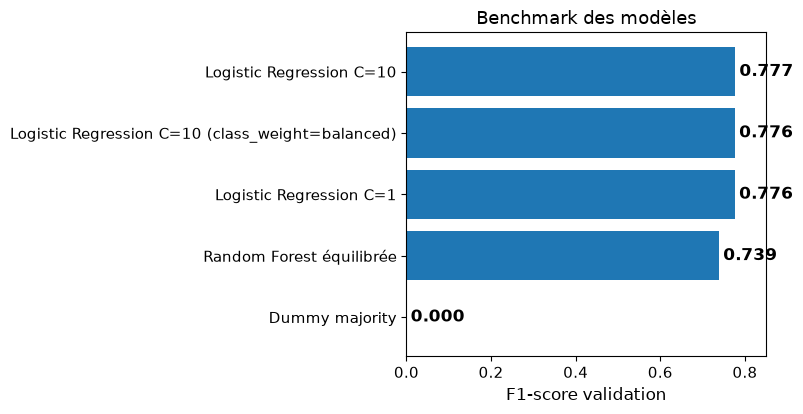

In [16]:
# ============================================================
# 6.2 Visualisation du benchmark
# ============================================================

# Le graphique montre rapidement quel modèle domine sur la métrique de certification.
plot_df = results_df.sort_values("valid_f1")

fig, ax = plt.subplots(figsize=(8, 4.3))
bars = ax.barh(plot_df["model"], plot_df["valid_f1"])
ax.set_xlim(0, max(0.85, plot_df["valid_f1"].max() + 0.05))
ax.set_xlabel("F1-score validation")
ax.set_title("Benchmark des modèles")

for bar, value in zip(bars, plot_df["valid_f1"], strict=True):
    ax.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontweight="bold",
    )

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

**Choix final.** La régression logistique régularisée est retenue car elle combine :

- un F1-score de validation supérieur ou équivalent aux alternatives testées (tableau ci-dessus) ;
- une très bonne lisibilité métier grâce aux coefficients ;
- un entraînement rapide et reproductible ;
- un risque d'overfitting plus contrôlé qu'un modèle non linéaire plus flexible.

**Déséquilibre de classes.** L'essai `class_weight="balanced"` ne change pas ce constat : une fois le seuil optimisé, son F1 est du même ordre que celui de la régression logistique sans pondération (colonne `valid_f1`), et son seuil optimal est très éloigné de 0,5 parce que les probabilités sont gonflées pour la classe rare. La pondération déplace le seuil mais n'améliore pas le F1 atteignable ; le modèle sans pondération est conservé, car ses probabilités restent plus proches de fréquences réelles. La **PR-AUC** (colonne `valid_pr_auc`) complète la ROC-AUC, qui flatte les classes rares.

**Pourquoi ne pas retenir uniquement Random Forest ?** Le modèle non linéaire est pertinent à tester, mais il est moins directement interprétable et n'améliore pas la métrique pour justifier cette perte de lisibilité dans ce cadre.

## 7. Résultats détaillés du meilleur modèle

In [17]:
# ============================================================
# 7.1 Extraction du meilleur modèle et calcul des prédictions validation
# ============================================================

# Le meilleur modèle est la première ligne du tableau trié par F1 validation.
best_row = results_df.iloc[0]
best_name = best_row["model"]
best_threshold = float(best_row["threshold"])
best_model = fitted_models[best_name]

# Probabilités de conversion sur la validation.
# On utilise ensuite le seuil optimisé pour obtenir des classes 0/1.
valid_proba = best_model.predict_proba(X_valid)[:, 1]
valid_pred = (valid_proba >= best_threshold).astype(int)

# Matrice de confusion : elle montre les vrais/faux positifs et négatifs.
cm = confusion_matrix(y_valid, valid_pred)

print("Meilleur modèle :", best_name)
print(f"Seuil optimisé : {best_threshold:.3f}")
print(f"F1 validation        : {f1_score(y_valid, valid_pred, zero_division=0):.4f}")
print(f"Precision validation : {precision_score(y_valid, valid_pred, zero_division=0):.4f}")
print(f"Recall validation    : {recall_score(y_valid, valid_pred, zero_division=0):.4f}")
print(f"Accuracy validation  : {accuracy_score(y_valid, valid_pred):.4f}")
print(f"ROC-AUC validation   : {roc_auc_score(y_valid, valid_proba):.4f}")
print(f"PR-AUC validation    : {average_precision_score(y_valid, valid_proba):.4f}")
print(f"(référence PR-AUC d'un modèle sans information : {y_valid.mean():.4f})")
print("\nClassification report :")
print(classification_report(y_valid, valid_pred, digits=4, zero_division=0))

Meilleur modèle : Logistic Regression C=10
Seuil optimisé : 0.450
F1 validation        : 0.7768
Precision validation : 0.8455
Recall validation    : 0.7184
Accuracy validation  : 0.9867
ROC-AUC validation   : 0.9869
PR-AUC validation    : 0.8481
(référence PR-AUC d'un modèle sans information : 0.0323)

Classification report :
              precision    recall  f1-score   support

           0     0.9907    0.9956    0.9931     55080
           1     0.8455    0.7184    0.7768      1836

    accuracy                         0.9867     56916
   macro avg     0.9181    0.8570    0.8850     56916
weighted avg     0.9860    0.9867    0.9862     56916



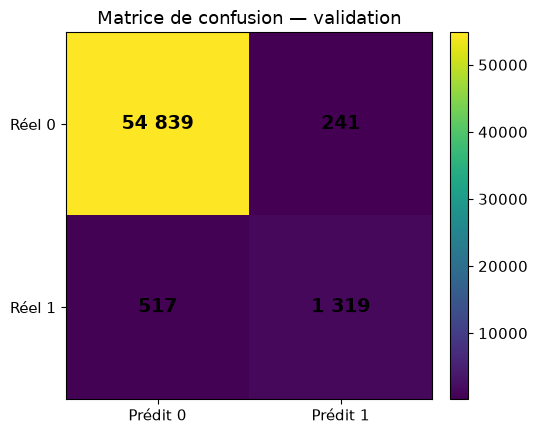

In [18]:
# ============================================================
# 7.2 Matrice de confusion
# ============================================================

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Prédit 0", "Prédit 1"])
ax.set_yticklabels(["Réel 0", "Réel 1"])
ax.set_title("Matrice de confusion — validation")

# Annotation des quatre cases pour que le graphique soit lisible en présentation.
for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            f"{cm[i, j]:,}".replace(",", " "),
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
        )

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

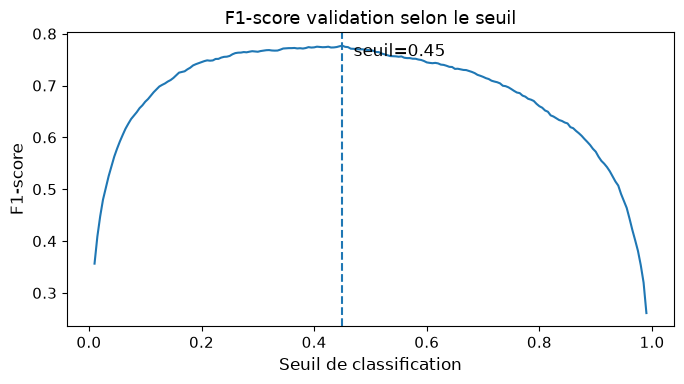

In [19]:
# ============================================================
# 7.3 Courbe F1 selon le seuil
# ============================================================

# Ce graphique justifie visuellement pourquoi le seuil n'est pas forcément 0.50.
threshold_grid = np.linspace(0.01, 0.99, 197)
f1_by_threshold = [
    f1_score(y_valid, valid_proba >= threshold, zero_division=0) for threshold in threshold_grid
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(threshold_grid, f1_by_threshold)
ax.axvline(best_threshold, linestyle="--")
ax.set_title("F1-score validation selon le seuil")
ax.set_xlabel("Seuil de classification")
ax.set_ylabel("F1-score")
ax.text(best_threshold + 0.02, max(f1_by_threshold) - 0.02, f"seuil={best_threshold:.2f}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "threshold_optimization.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

**Lecture métier de la matrice de confusion.** Le modèle détecte une partie importante des convertisseurs avec un nombre limité de faux positifs. Le seuil retenu maximise le F1-score, mais il peut être déplacé si le métier préfère une stratégie plus agressive en rappel ou plus stricte en précision.

## 7 bis. Validation croisée K-Fold stratifiée

Le référentiel du bloc 3 cite nommément « l'utilisation de la K-Fold Crossvalidation et [des]
tests de vérification de sur-entrainement et sous-entrainement ». Le F1 de la section 7 repose sur
**un seul** découpage 80/20 : il pourrait être favorable par hasard. La K-Fold répète la mesure
sur **cinq** découpages et donne la moyenne **et** la dispersion.

**Pourquoi `StratifiedKFold` ?** Les convertis sont rares : chaque pli doit garder la même
proportion de convertis, sinon le F1 varierait pour une raison purement mécanique.

In [20]:
# =============================================================================
# 7 bis — Validation croisée K-Fold stratifiée (5 plis)
# =============================================================================
# shuffle=True + random_state : les 5 plis sont tirés au hasard, mais toujours
# les mêmes d'une exécution à l'autre (reproductibilité).
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Le pipeline retenu, reconstruit À L'IDENTIQUE de la section 6 : même prétraitement
# (imputation + standardisation + one-hot), même C=10, même solveur. make_model_pipeline
# clone le prétraitement : la validation croisée n'altère aucun objet déjà ajusté.
pipeline_retenu = make_model_pipeline(
    preprocess_linear, LogisticRegression(C=10, **LOGISTIC_PARAMS)
)

# La référence : un modèle qui prédit toujours « non converti ». Son F1 sur la
# classe positive est nul ; tout modèle utile doit faire mieux.
pipeline_reference = make_model_pipeline(
    preprocess_tree, DummyClassifier(strategy="most_frequent")
)

# Scoreurs avec zero_division=0 : quand un modèle ne prédit aucun positif (la référence),
# la précision n'est pas définie ; on la fixe à 0 plutôt que de laisser un avertissement.
SCORERS = {
    "f1": make_scorer(f1_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "pr_auc": "average_precision",
}

# --- 1) Scores au seuil standard (0,5), apprentissage ET validation ---------
lignes = []
for nom, pipe in [
    ("Référence (classe majoritaire)", pipeline_reference),
    ("Régression logistique retenue", pipeline_retenu),
]:
    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=kfold,
        scoring=SCORERS,
        return_train_score=True,
    )
    lignes.append(
        {
            "modèle": nom,
            "F1 validation (moyenne 5 plis)": scores["test_f1"].mean(),
            "F1 validation (écart-type)": scores["test_f1"].std(),
            "F1 apprentissage (moyenne)": scores["train_f1"].mean(),
            "rappel validation": scores["test_recall"].mean(),
            "précision validation": scores["test_precision"].mean(),
            "PR-AUC validation": scores["test_pr_auc"].mean(),
        }
    )
tableau_kfold = pd.DataFrame(lignes)
tableau_kfold["écart apprentissage − validation"] = (
    tableau_kfold["F1 apprentissage (moyenne)"] - tableau_kfold["F1 validation (moyenne 5 plis)"]
)
afficher(tableau_kfold.round(4))

# --- 2) F1 au SEUIL OPTIMISÉ de la section 5, pli par pli -------------------
# cross_val_predict renvoie, pour chaque ligne, la probabilité calculée par le
# modèle du pli qui ne l'a PAS vue à l'entraînement (prédiction « hors pli »).
# On applique ensuite le seuil best_threshold choisi en section 5.
proba_hors_pli = cross_val_predict(
    pipeline_retenu, X_train, y_train, cv=kfold, method="predict_proba"
)[:, 1]
f1_par_pli = []
for _, idx_valid in kfold.split(X_train, y_train):
    y_vrai = y_train.iloc[idx_valid]
    y_prevu = (proba_hors_pli[idx_valid] >= best_threshold).astype(int)
    f1_par_pli.append(f1_score(y_vrai, y_prevu, zero_division=0))
print(
    f"F1 au seuil optimisé ({best_threshold:.2f}), pli par pli : "
    + ", ".join(f"{v:.4f}" for v in f1_par_pli)
)
print(f"Moyenne {np.mean(f1_par_pli):.4f} — écart-type {np.std(f1_par_pli):.4f}")

# --- 3) Diagnostic, calculé à partir des chiffres ci-dessus -----------------
ecart = tableau_kfold.loc[1, "écart apprentissage − validation"]
dispersion = float(np.std(f1_par_pli))
f1_reference = tableau_kfold.loc[0, "F1 validation (moyenne 5 plis)"]
f1_modele = tableau_kfold.loc[1, "F1 validation (moyenne 5 plis)"]
print("Diagnostic :")
print(
    f"- sur-apprentissage : écart apprentissage − validation = {ecart:.4f} → "
    + lecture_ecart_apprentissage(ecart)
)
print(
    f"- stabilité : écart-type du F1 entre plis = {dispersion:.4f} → "
    + lecture_stabilite(dispersion)
)
print(
    f"- sous-apprentissage : F1 de la référence {f1_reference:.4f} contre "
    f"{f1_modele:.4f} pour le modèle retenu → le modèle apprend un signal réel"
)

,modèle,F1 validation (moyenne 5 plis),F1 validation (écart-type),F1 apprentissage (moyenne),rappel validation,précision validation,PR-AUC validation,écart apprentissage − validation
0,Référence (classe majoritaire),0.0000,0.0000,0.0000,0.0000,0.0000,0.0323,0.0000
1,Régression logistique retenue,0.7621,0.0067,0.7623,0.6882,0.8538,0.8426,0.0003


F1 au seuil optimisé (0.45), pli par pli : 0.7616, 0.7690, 0.7761, 0.7694, 0.7595
Moyenne 0.7671 — écart-type 0.0060
Diagnostic :
- sur-apprentissage : écart apprentissage − validation = 0.0003 → négligeable
- stabilité : écart-type du F1 entre plis = 0.0060 → score stable, indépendant du découpage
- sous-apprentissage : F1 de la référence 0.0000 contre 0.7621 pour le modèle retenu → le modèle apprend un signal réel


## 8. Test de zone d’ombre : que se passe-t-il sans `total_pages_visited` ?

In [21]:
# ============================================================
# 8.1 Modèle alternatif sans la variable d'engagement
# ============================================================

# total_pages_visited soulève une question légitime :
# est-ce une fuite de données ?
# Réponse : cela dépend du moment de scoring.
# - Si on score pendant ou après la session, la variable est disponible et légitime.
# - Si on veut prédire avant toute navigation, cette variable n'est pas encore connue.
# Et même quand elle est disponible, elle reste un INDICATEUR d'intention (voir section 9) :
# le lien avec la conversion peut aller de l'intention vers le nombre de pages.
#
# Pour couvrir cette zone d'ombre, on entraîne une variante sans cette variable.
cols_without_pages = [col for col in X.columns if col != "total_pages_visited"]
X_train_no_pages = X_train[cols_without_pages]
X_valid_no_pages = X_valid[cols_without_pages]

num_cols_no_pages = ["age", "new_user"]
cat_cols_no_pages = ["country", "source"]

preprocess_no_pages = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            num_cols_no_pages,
        ),
        ("cat", make_one_hot_encoder(drop="first"), cat_cols_no_pages),
    ],
    verbose_feature_names_out=False,
)

model_no_pages = make_model_pipeline(
    preprocess_no_pages, LogisticRegression(C=10, **LOGISTIC_PARAMS)
)

model_no_pages.fit(X_train_no_pages, y_train)
proba_no_pages = model_no_pages.predict_proba(X_valid_no_pages)[:, 1]
threshold_no_pages, f1_no_pages = optimize_threshold(y_valid, proba_no_pages)
pred_no_pages = (proba_no_pages >= threshold_no_pages).astype(int)

leakage_test = pd.DataFrame(
    [
        {
            "scenario": "Modèle final avec total_pages_visited",
            "threshold": best_threshold,
            "valid_f1": f1_score(y_valid, valid_pred, zero_division=0),
            "valid_precision": precision_score(y_valid, valid_pred, zero_division=0),
            "valid_recall": recall_score(y_valid, valid_pred, zero_division=0),
            "valid_roc_auc": roc_auc_score(y_valid, valid_proba),
            "valid_pr_auc": average_precision_score(y_valid, valid_proba),
        },
        {
            "scenario": "Variante pré-visite sans total_pages_visited",
            "threshold": threshold_no_pages,
            "valid_f1": f1_no_pages,
            "valid_precision": precision_score(y_valid, pred_no_pages, zero_division=0),
            "valid_recall": recall_score(y_valid, pred_no_pages, zero_division=0),
            "valid_roc_auc": roc_auc_score(y_valid, proba_no_pages),
            "valid_pr_auc": average_precision_score(y_valid, proba_no_pages),
        },
    ]
)

afficher(leakage_test)

,scenario,threshold,valid_f1,valid_precision,valid_recall,valid_roc_auc,valid_pr_auc
0,Modèle final avec total_pages_visited,0.450,0.776796,0.845513,0.718410,0.986900,0.848141
1,Variante pré-visite sans total_pages_visited,0.095,0.212528,0.140595,0.435185,0.822498,0.133850


**`total_pages_visited` : disponibilité et nature de la variable.** Cette variable est le meilleur **indicateur d'intention** disponible dans les données. Elle est acceptable si l'entreprise score un visiteur pendant la session ou à la fin de la session. En revanche, pour une prédiction avant toute navigation, il faut utiliser la variante sans cette variable et accepter une performance beaucoup plus faible (tableau ci-dessus). Le choix dépend donc du cas d'usage opérationnel, pas seulement de la statistique. Ce n'est pas non plus un levier prouvé : le nombre de pages vues est observé en même temps que l'intention (causalité inverse possible).

## 9. Interprétation du modèle et recommandations métier

In [22]:
# ============================================================
# 9.1 Coefficients de la régression logistique
# ============================================================

# L'interprétation par coefficients est possible parce que le modèle final est linéaire.
# Les coefficients positifs augmentent les log-odds de conversion ;
# les coefficients négatifs les diminuent.
# Attention : ce sont des associations prédictives, pas des preuves causales.
logistic_model = fitted_models.get("Logistic Regression C=10", best_model)

# Récupération des noms de variables après preprocessing.
# Cela associe chaque coefficient à sa variable transformée.
feature_names = logistic_model.named_steps["preprocess"].get_feature_names_out()
coefs = logistic_model.named_steps["model"].coef_[0]

coef_df = (
    pd.DataFrame(
        {
            "feature": feature_names,
            "coefficient": coefs,
            "abs_coefficient": np.abs(coefs),
        }
    )
    .sort_values("abs_coefficient", ascending=False)
    .reset_index(drop=True)
)
coef_df["rang |coefficient|"] = coef_df.index + 1
afficher(coef_df)

# Modalités de référence (drop='first') : les coefficients de pays et de source sont des
# écarts avec cette modalité. Un fort coefficient de pays mesure donc surtout l'écart avec
# le pays de référence, très peu convertisseur (voir l'EDA), pas une « force » absolue.
encodeur = logistic_model.named_steps["preprocess"].named_transformers_["cat"]
pays_reference = str(encodeur.categories_[0][0])
source_reference = str(encodeur.categories_[1][0])
print(f"Modalités de référence : country = {pays_reference}, source = {source_reference}")

,feature,coefficient,abs_coefficient,rang |coefficient|
0,country_Germany,3.741961,3.741961,1
1,country_UK,3.560472,3.560472,2
2,country_US,3.216221,3.216221,3
3,total_pages_visited,2.529309,2.529309,4
4,new_user,-0.785388,0.785388,5
5,age,-0.599671,0.599671,6
6,source_Direct,-0.209163,0.209163,7
7,source_Seo,-0.037690,0.037690,8


Modalités de référence : country = China, source = Ads


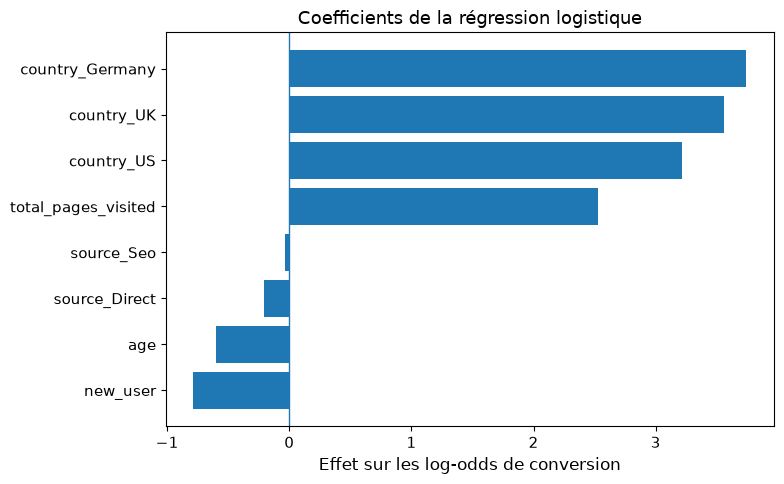

In [23]:
# ============================================================
# 9.2 Graphique des coefficients
# ============================================================

# On trie par coefficient pour distinguer les effets négatifs et positifs.
coef_plot = coef_df.sort_values("coefficient")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coef_plot["feature"], coef_plot["coefficient"])
ax.axvline(0, linewidth=1)
ax.set_title("Coefficients de la régression logistique")
ax.set_xlabel("Effet sur les log-odds de conversion")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "logistic_coefficients.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

In [24]:
# ============================================================
# 9.3 Recommandations (texte calculé à partir des résultats ci-dessus)
# ============================================================
# Les chiffres viennent des variables calculées plus haut (EDA, coefficients).
rang_pages = int(coef_df.index[coef_df["feature"] == "total_pages_visited"][0] + 1)
taux_chine = float(country_summary.loc["China", "conversion_rate"])
taux_pays_hors_chine = float(train.loc[train["country"] != "China", "converted"].mean())
taux_retour = float(new_user_summary.loc["Returning user", "conversion_rate"])
taux_nouveau = float(new_user_summary.loc["New user", "conversion_rate"])
source_min = source_summary["conversion_rate"].idxmin()
source_max = source_summary["conversion_rate"].idxmax()

afficher_markdown(
    f"""
### Recommandations actionnables

1. **Lire `total_pages_visited` comme un indicateur d'intention, pas comme un levier prouvé.**
   La conversion est de {taux_16_20:.1%} entre 16 et 20 pages et de {taux_21_plus:.0%} au-delà
   de 21 pages (n = {n_21_plus}). Mais la variable est observée pendant la session : un
   visiteur décidé à s'abonner parcourt plus de pages (**causalité inverse** possible). Par
   valeur absolue du coefficient standardisé, elle n'arrive qu'en position {rang_pages}, derrière
   les indicatrices de pays, qui mesurent l'écart avec le pays de référence ({pays_reference}).
   Usage défendable : **déclencher la demande d'inscription quand l'intention devient
   observable** (nombre de pages atteint), à valider par A/B test ; non défendable : affirmer
   qu'augmenter le nombre de pages vues fait augmenter la conversion.
2. **Travailler la réactivation.** Les visiteurs récurrents convertissent {taux_retour:.1%}
   contre {taux_nouveau:.1%} pour les nouveaux : retargeting, rappel, contenu personnalisé pour
   les visiteurs déjà connus.
3. **Adapter l'approche par pays.** La Chine convertit {taux_chine:.2%}, contre
   {taux_pays_hors_chine:.2%} pour l'ensemble des autres pays : vérifier langue, performance du
   site, proposition de valeur locale, acquisition et conformité.
4. **Segmenter les messages d'acquisition.** Les écarts entre sources existent mais sont
   modestes (de {source_summary["conversion_rate"].min():.2%} pour {source_min} à
   {source_summary["conversion_rate"].max():.2%} pour {source_max}) : suivre le coût par
   conversion et tester des landing pages dédiées.
5. **Valider les recommandations par expérimentation.** Le modèle montre des associations
   prédictives ; les décisions marketing doivent ensuite être confirmées par A/B tests.

**À retenir :** l'interprétation de coefficients n'est pas une preuve de
causalité. Elle sert à prioriser des hypothèses d'action.
"""
)


### Recommandations actionnables

1. **Lire `total_pages_visited` comme un indicateur d'intention, pas comme un levier prouvé.**
   La conversion est de 93.2% entre 16 et 20 pages et de 100% au-delà
   de 21 pages (n = 626). Mais la variable est observée pendant la session : un
   visiteur décidé à s'abonner parcourt plus de pages (**causalité inverse** possible). Par
   valeur absolue du coefficient standardisé, elle n'arrive qu'en position 4, derrière
   les indicatrices de pays, qui mesurent l'écart avec le pays de référence (China).
   Usage défendable : **déclencher la demande d'inscription quand l'intention devient
   observable** (nombre de pages atteint), à valider par A/B test ; non défendable : affirmer
   qu'augmenter le nombre de pages vues fait augmenter la conversion.
2. **Travailler la réactivation.** Les visiteurs récurrents convertissent 7.2%
   contre 1.4% pour les nouveaux : retargeting, rappel, contenu personnalisé pour
   les visiteurs déjà connus.
3. **Adapter l'approche par pays.** La Chine convertit 0.13%, contre
   4.22% pour l'ensemble des autres pays : vérifier langue, performance du
   site, proposition de valeur locale, acquisition et conformité.
4. **Segmenter les messages d'acquisition.** Les écarts entre sources existent mais sont
   modestes (de 2.78% pour Direct à
   3.48% pour Ads) : suivre le coût par
   conversion et tester des landing pages dédiées.
5. **Valider les recommandations par expérimentation.** Le modèle montre des associations
   prédictives ; les décisions marketing doivent ensuite être confirmées par A/B tests.

**À retenir :** l'interprétation de coefficients n'est pas une preuve de
causalité. Elle sert à prioriser des hypothèses d'action.


## 10. Entraînement final et fichier de soumission

In [25]:
# ============================================================
# 10.1 Entraînement final sur 100 % du train
# ============================================================

# Une fois le modèle choisi et évalué sur validation, on le réentraîne sur tout le train.
# Pourquoi ? Parce que pour la soumission finale, on veut exploiter toutes les données labellisées
# disponibles.
# Le seuil, lui, reste celui choisi sur validation pour éviter d'utiliser le test non labellisé.
# make_model_pipeline clone le prétraitement : ce réentraînement ne touche pas aux objets
# déjà ajustés pour l'évaluation.
final_model = make_model_pipeline(preprocess_linear, LogisticRegression(C=10, **LOGISTIC_PARAMS))

final_model.fit(X, y)

# Prédiction des probabilités sur le fichier test non labellisé.
test_proba = final_model.predict_proba(test)[:, 1]

# Transformation des probabilités en classes 0/1 avec le seuil optimisé sur validation.
test_pred = (test_proba >= best_threshold).astype(int)

# Format attendu pour la soumission : une colonne converted, sans index.
# lineterminator="\n" : fins de ligne LF sur tous les systèmes.
submission = pd.DataFrame({"converted": test_pred})
submission_path = DATA_DIR / "conversion_data_test_predictions_CDSD_Bloc3_LogReg_commente.csv"
submission.to_csv(submission_path, index=False, lineterminator="\n")

# Fichier complémentaire non nécessaire au leaderboard, mais utile pour l'analyse métier :
# il permet de prioriser les visiteurs selon leur probabilité de conversion.
probability_path = (
    DATA_DIR / "conversion_data_test_predictions_with_probabilities_CDSD_Bloc3_LogReg_commente.csv"
)
pd.DataFrame(
    {
        "converted": test_pred,
        "conversion_probability": test_proba,
    }
).to_csv(probability_path, index=False, lineterminator="\n")

# Contrôles du format de soumission : une seule colonne « converted », une ligne par ligne
# du fichier test, uniquement des 0 et des 1.
assert list(submission.columns) == ["converted"]
assert len(submission) == len(test)
assert set(submission["converted"].unique()) <= {0, 1}

print("Fichier de soumission créé :", submission_path.name)
print("Fichier avec probabilités créé :", probability_path.name)
print("Shape submission:", submission.shape)
print(f"Taux de positifs prédits sur le test : {submission['converted'].mean():.2%}")
afficher(submission.head())

Fichier de soumission créé : conversion_data_test_predictions_CDSD_Bloc3_LogReg_commente.csv
Fichier avec probabilités créé : conversion_data_test_predictions_with_probabilities_CDSD_Bloc3_LogReg_commente.csv
Shape submission: (31620, 1)
Taux de positifs prédits sur le test : 2.75%


**Pourquoi entraîner sur 100 % du train après validation ?** La validation sert à choisir le modèle et le seuil. Une fois ces choix figés, réentraîner sur toutes les données labellisées donne au modèle le maximum d’information disponible avant de prédire le test.

**Pourquoi fournir aussi les probabilités ?** Le fichier de soumission ne doit contenir que `converted`, mais les probabilités sont utiles pour une équipe métier : elles permettent de prioriser les visiteurs à cibler.

## 11. Extension non supervisée — segmentation des visiteurs

In [26]:
# ============================================================
# 11.1 Préprocessing pour clustering
# ============================================================

# Objectif : segmenter les visiteurs en groupes homogènes sans utiliser la cible converted.
# Cela couvre la compétence non supervisée du Bloc 3.
#
# Pour KMeans, la standardisation est importante : sans scaler, une variable à grande échelle
# dominerait artificiellement les distances euclidiennes.
preprocess_cluster = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            num_cols,
        ),
        ("cat", make_one_hot_encoder(drop=None), cat_cols),
    ],
    verbose_feature_names_out=False,
)

# On ajuste le preprocessing sur X uniquement, sans la cible.
# Le clustering ne doit pas apprendre à partir de converted.
Z = preprocess_cluster.fit_transform(X)

# Deux échantillons DISJOINTS, tirés une fois pour toutes :
# - un échantillon d'apprentissage (30 000 lignes) pour placer les centres de KMeans ;
# - un échantillon d'évaluation (10 000 lignes) pour mesurer silhouette et Davies-Bouldin.
# Évaluer sur des lignes que KMeans n'a pas vues évite une mesure trop favorable.
# (La silhouette demande de calculer toutes les distances deux à deux : on ne peut pas
# l'évaluer sur 284 580 lignes ; 10 000 donnent une estimation stable.)
TAILLE_APPRENTISSAGE = 30_000
TAILLE_EVALUATION = 10_000
rng = np.random.default_rng(RANDOM_STATE)
ordre = rng.permutation(len(X))
idx_fit = ordre[:TAILLE_APPRENTISSAGE]
idx_eval = ordre[TAILLE_APPRENTISSAGE : TAILLE_APPRENTISSAGE + TAILLE_EVALUATION]
Z_fit = Z[idx_fit]
Z_eval = Z[idx_eval]

print("Shape après preprocessing clustering :", Z.shape)
print("Échantillon d'apprentissage :", len(Z_fit), "| échantillon d'évaluation :", len(Z_eval))

Shape après preprocessing clustering : (284580, 10)
Échantillon d'apprentissage : 30000 | échantillon d'évaluation : 10000


,k,inertie,silhouette,Davies-Bouldin,baisse d'inertie vs k-1 (%)
0,2,95879.636,0.279,1.592,NaN
1,3,82045.660,0.202,1.674,14.428
2,4,71112.964,0.215,1.480,13.325
3,5,65560.516,0.204,1.582,7.808
4,6,60440.540,0.198,1.569,7.810
5,7,56731.681,0.188,1.618,6.136
6,8,54315.601,0.184,1.730,4.259


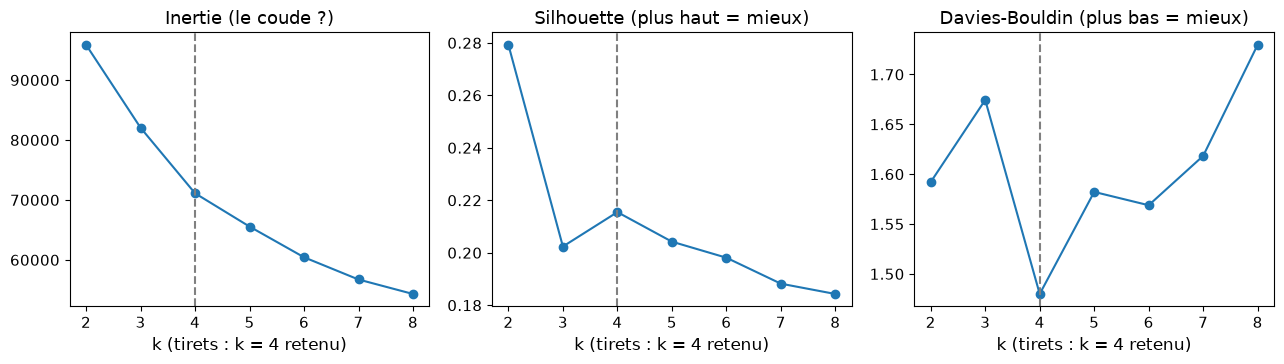


**Lecture.** L'inertie baisse régulièrement : **aucun coude net** ne désigne un k. La
silhouette est maximale pour **k=2** (0.279) ; pour k=4 elle vaut
0.215. L'indice de Davies-Bouldin est minimal pour **k=4**
(1.480) ; pour k=4 il vaut 1.480. Aucune métrique ne tranche donc seule :
**k=4 est assumé comme un choix métier** (voir ci-dessous), appuyé par ces mesures plutôt que
décidé par elles.


In [27]:
# ============================================================
# 11.2 Choix de k : inertie, silhouette et Davies-Bouldin
# ============================================================

# Trois lectures complémentaires, pour k de 2 à 8 :
# - l'inertie (compacité des clusters) diminue toujours quand k augmente : on cherche un
#   « coude », c'est-à-dire un k au-delà duquel le gain devient faible ;
# - la silhouette (plus haut = mieux, entre -1 et 1) compare la cohésion d'un point à sa
#   séparation avec le cluster voisin ;
# - l'indice de Davies-Bouldin (plus BAS = mieux) mesure le chevauchement moyen des clusters.
# Réglages : n_init=10 initialisations et jusqu'à 300 itérations pour des centres stables.
lignes_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, max_iter=300)
    km.fit(Z_fit)
    etiquettes_eval = km.predict(Z_eval)
    lignes_k.append(
        {
            "k": k,
            "inertie": km.inertia_,
            "silhouette": silhouette_score(Z_eval, etiquettes_eval),
            "Davies-Bouldin": davies_bouldin_score(Z_eval, etiquettes_eval),
        }
    )

k_table = pd.DataFrame(lignes_k)
k_table["baisse d'inertie vs k-1 (%)"] = -100 * k_table["inertie"].pct_change()
afficher(k_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, colonne, titre in [
    (axes[0], "inertie", "Inertie (le coude ?)"),
    (axes[1], "silhouette", "Silhouette (plus haut = mieux)"),
    (axes[2], "Davies-Bouldin", "Davies-Bouldin (plus bas = mieux)"),
]:
    ax.plot(k_table["k"], k_table[colonne], marker="o")
    ax.axvline(4, linestyle="--", color="gray")
    ax.set_title(titre)
    ax.set_xlabel("k (tirets : k = 4 retenu)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "kmeans_elbow.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

k_silhouette = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
k_davies_bouldin = int(k_table.loc[k_table["Davies-Bouldin"].idxmin(), "k"])
silhouette_4 = float(k_table.loc[k_table["k"] == 4, "silhouette"].iloc[0])
silhouette_max = float(k_table["silhouette"].max())
db_4 = float(k_table.loc[k_table["k"] == 4, "Davies-Bouldin"].iloc[0])
db_min = float(k_table["Davies-Bouldin"].min())

afficher_markdown(
    f"""
**Lecture.** L'inertie baisse régulièrement : **aucun coude net** ne désigne un k. La
silhouette est maximale pour **k={k_silhouette}** ({silhouette_max:.3f}) ; pour k=4 elle vaut
{silhouette_4:.3f}. L'indice de Davies-Bouldin est minimal pour **k={k_davies_bouldin}**
({db_min:.3f}) ; pour k=4 il vaut {db_4:.3f}. Aucune métrique ne tranche donc seule :
**k=4 est assumé comme un choix métier** (voir ci-dessous), appuyé par ces mesures plutôt que
décidé par elles.
"""
)

In [28]:
# ============================================================
# 11.3 KMeans : ce que k=2 sépare, et ce que k=4 ajoute
# ============================================================

# Pourquoi comparer k=2 et k=4 ? Si k=2 maximise la silhouette, il faut montrer ce qu'il
# sépare réellement, pour que le choix de k=4 soit un arbitrage visible et non un oubli.


# resume_clusters(X, y, etiquettes) est dans conversion_bloc3.py (testée dans tests/) : tableau
# de synthèse par cluster ; la cible n'est utilisée qu'ICI, pour interpréter.


# k=2 : ce que la silhouette « préfère ».
kmeans_2 = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10, max_iter=300)
kmeans_2.fit(Z_fit)
print("k=2 (silhouette maximale) :")
afficher(resume_clusters(X, y, kmeans_2.predict(Z)).round(3))

# k=4 : le choix retenu. Les centres sont appris sur l'échantillon d'apprentissage, puis
# chaque visiteur est affecté au cluster le plus proche.
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10, max_iter=300)
kmeans.fit(Z_fit)
clusters = kmeans.predict(Z)

# La cible converted est ajoutée seulement après le clustering pour interpréter les groupes.
# Elle n'est pas utilisée par KMeans pendant l'apprentissage.
cluster_summary = resume_clusters(X, y, clusters)
print("k=4 (retenu) :")
afficher(cluster_summary.round(3))

k=2 (silhouette maximale) :


,n,conversion_rate,age_mean,new_user_rate,pages_mean,china_share,us_share,ads_share,direct_share,seo_share
cluster,,,,,,,,,,
1,89514,0.072,30.422,0.0,5.283,0.232,0.569,0.280,0.228,0.491
0,195066,0.014,30.630,1.0,4.685,0.248,0.560,0.282,0.229,0.489


k=4 (retenu) :


,n,conversion_rate,age_mean,new_user_rate,pages_mean,china_share,us_share,ads_share,direct_share,seo_share
cluster,,,,,,,,,,
3,29521,0.287,27.820,0.610,11.893,0.177,0.589,0.287,0.222,0.491
0,77456,0.007,30.671,0.000,4.131,0.249,0.562,0.278,0.230,0.492
2,73459,0.001,39.246,0.993,4.244,0.248,0.565,0.281,0.226,0.493
1,104144,0.001,25.139,1.000,3.879,0.254,0.554,0.282,0.232,0.487


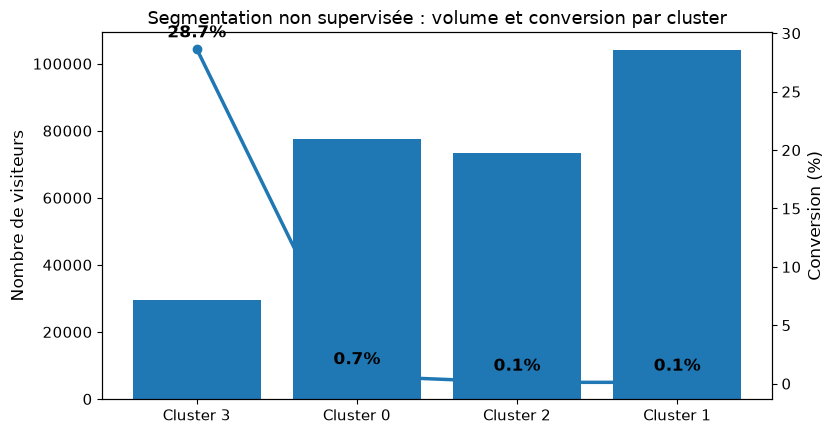

In [29]:
# ============================================================
# 11.4 Visualisation volume + conversion par cluster
# ============================================================

cluster_plot = cluster_summary.reset_index().copy()
cluster_plot["cluster_label"] = cluster_plot["cluster"].apply(lambda c: f"Cluster {c}")

fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
x = np.arange(len(cluster_plot))

# Volume par cluster.
ax1.bar(x, cluster_plot["n"])
ax1.set_ylabel("Nombre de visiteurs")
ax1.set_xticks(x)
ax1.set_xticklabels(cluster_plot["cluster_label"])

# Taux de conversion par cluster.
ax2 = ax1.twinx()
ax2.plot(x, cluster_plot["conversion_rate"] * 100, marker="o", linewidth=2.5)
ax2.set_ylabel("Conversion (%)")
ax2.grid(False)

for i, row in cluster_plot.iterrows():
    ax2.text(
        i,
        row["conversion_rate"] * 100 + 1,
        f"{row['conversion_rate'] * 100:.1f}%",
        ha="center",
        fontweight="bold",
    )

ax1.set_title("Segmentation non supervisée : volume et conversion par cluster")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cluster_summary.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

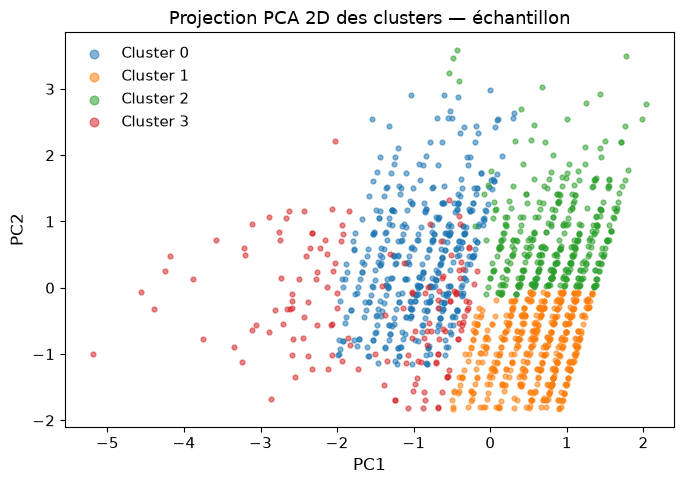

Variance expliquée par PC1 + PC2 : 49.13%


In [30]:
# ============================================================
# 11.5 Projection PCA pour visualiser les clusters
# ============================================================

# PCA n'est pas utilisée pour entraîner KMeans ici.
# Elle sert uniquement à projeter les données en 2D et produire une visualisation lisible.
pca_sample_size = min(1500, len(X))
pca_idx = rng.choice(len(X), size=pca_sample_size, replace=False)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(Z[pca_idx])

pca_df = pd.DataFrame(
    {
        "PC1": coords[:, 0],
        "PC2": coords[:, 1],
        "cluster": clusters[pca_idx],
        "converted": y.iloc[pca_idx].values,
    }
)

fig, ax = plt.subplots(figsize=(7, 5))
for cluster_id, group in pca_df.groupby("cluster"):
    ax.scatter(
        group["PC1"],
        group["PC2"],
        s=12,
        alpha=0.55,
        label=f"Cluster {cluster_id}",
    )

ax.set_title("Projection PCA 2D des clusters — échantillon")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(frameon=False, markerscale=1.8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pca_clusters.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Variance expliquée par PC1 + PC2 : {pca.explained_variance_ratio_.sum():.2%}")

In [31]:
# ============================================================
# 11.6 Lecture des clusters (texte calculé à partir du tableau 11.3)
# ============================================================
# Le cluster « haute intention » est celui dont le nombre moyen de pages est le plus élevé ;
# les autres sont décrits par ce qui les distingue réellement dans le tableau.
haute = cluster_summary["pages_mean"].idxmax()
autres = cluster_summary.drop(index=haute)
ligne_haute = cluster_summary.loc[haute]
part_haute = ligne_haute["n"] / cluster_summary["n"].sum()

# Provenance : si les clusters ont des parts de sources quasi égales, la provenance ne les
# distingue pas ; on le vérifie par l'écart maximal entre clusters.
ecart_ads = cluster_summary["ads_share"].max() - cluster_summary["ads_share"].min()
ecart_direct = cluster_summary["direct_share"].max() - cluster_summary["direct_share"].min()
ecart_source = max(ecart_ads, ecart_direct)


# statut_visiteurs(taux_nouveaux) est dans conversion_bloc3.py (testée dans tests/) : phrase
# courte sur la part de nouveaux visiteurs d'un cluster.


lignes_autres = []
for numero, ligne in autres.sort_values("age_mean").iterrows():
    effectif = f"{int(ligne['n']):,}".replace(",", " ")
    lignes_autres.append(
        f"- **cluster {numero}** ({effectif} visiteurs) : âge moyen {ligne['age_mean']:.1f} ans, "
        f"{statut_visiteurs(ligne['new_user_rate'])}, {ligne['pages_mean']:.1f} pages en "
        f"moyenne, conversion {ligne['conversion_rate']:.2%}."
    )
texte_autres = "\n".join(lignes_autres)
effectif_haute = f"{int(ligne_haute['n']):,}".replace(",", " ")

afficher_markdown(
    f"""
**Interprétation de la segmentation (k=4).**

- **Un seul cluster se distingue par l'intention** : le cluster {haute}
  ({effectif_haute} visiteurs, {part_haute:.1%} du total) compte
  {ligne_haute["pages_mean"]:.1f} pages en moyenne contre {autres["pages_mean"].min():.1f} à
  {autres["pages_mean"].max():.1f} pour les trois autres, et une conversion de
  {ligne_haute["conversion_rate"]:.1%} contre {autres["conversion_rate"].min():.2%} à
  {autres["conversion_rate"].max():.2%}.
- **Les trois autres clusters se distinguent par l'âge et le statut nouveau / récurrent**, pas
  par la provenance :

{texte_autres}

- **La provenance ne distingue pas les clusters** : les parts de Ads et de Direct varient de
  moins de {100 * ecart_source:.1f} points d'un cluster à l'autre (Ads : de
  {cluster_summary["ads_share"].min():.1%} à {cluster_summary["ads_share"].max():.1%} ;
  Direct : de {cluster_summary["direct_share"].min():.1%} à
  {cluster_summary["direct_share"].max():.1%}).

Cette segmentation permet de personnaliser les parcours sans utiliser la cible `converted`
dans l'apprentissage non supervisé. Réserve : le cluster à forte intention est défini surtout
par `total_pages_visited` ; il repère des visiteurs déjà engagés, il n'explique pas pourquoi ils
le sont (même réserve de causalité inverse qu'en section 9).

**Pourquoi KMeans ?** KMeans est simple, rapide et adapté à ce cadre. Comme les
variables numériques sont standardisées et les catégories one-hot encodées, la distance utilisée
par KMeans est plus cohérente. Pour une étude plus avancée, on pourrait comparer avec DBSCAN, un
clustering hiérarchique ou des mélanges gaussiens.
"""
)


**Interprétation de la segmentation (k=4).**

- **Un seul cluster se distingue par l'intention** : le cluster 3
  (29 521 visiteurs, 10.4% du total) compte
  11.9 pages en moyenne contre 3.9 à
  4.2 pour les trois autres, et une conversion de
  28.7% contre 0.11% à
  0.67%.
- **Les trois autres clusters se distinguent par l'âge et le statut nouveau / récurrent**, pas
  par la provenance :

- **cluster 1** (104 144 visiteurs) : âge moyen 25.1 ans, uniquement des nouveaux visiteurs, 3.9 pages en moyenne, conversion 0.11%.
- **cluster 0** (77 456 visiteurs) : âge moyen 30.7 ans, uniquement des visiteurs récurrents, 4.1 pages en moyenne, conversion 0.67%.
- **cluster 2** (73 459 visiteurs) : âge moyen 39.2 ans, uniquement des nouveaux visiteurs, 4.2 pages en moyenne, conversion 0.11%.

- **La provenance ne distingue pas les clusters** : les parts de Ads et de Direct varient de
  moins de 0.9 points d'un cluster à l'autre (Ads : de
  27.8% à 28.7% ;
  Direct : de 22.2% à
  23.2%).

Cette segmentation permet de personnaliser les parcours sans utiliser la cible `converted`
dans l'apprentissage non supervisé. Réserve : le cluster à forte intention est défini surtout
par `total_pages_visited` ; il repère des visiteurs déjà engagés, il n'explique pas pourquoi ils
le sont (même réserve de causalité inverse qu'en section 9).

**Pourquoi KMeans ?** KMeans est simple, rapide et adapté à ce cadre. Comme les
variables numériques sont standardisées et les catégories one-hot encodées, la distance utilisée
par KMeans est plus cohérente. Pour une étude plus avancée, on pourrait comparer avec DBSCAN, un
clustering hiérarchique ou des mélanges gaussiens.


In [32]:
# ============================================================
# 11 bis. Conformité RGPD des données de navigation (texte calculé)
# ============================================================
# Les chiffres d'unicité viennent de la cellule 3.5 (n_profils, lignes_uniques, part_uniques).
nb_lignes = f"{len(train):,}".replace(",", " ")
nb_profils = f"{n_profils:,}".replace(",", " ")
nb_uniques = f"{lignes_uniques:,}".replace(",", " ")

# Tableau des principes du RGPD appliqués au projet (une ligne = un principe), construit en
# Python pour garder des lignes de code courtes.
lignes_rgpd = [
    (
        "Base légale (art. 6)",
        (
            "Mesure d'audience et amélioration du service : intérêt légitime de l'éditeur, ou "
            "consentement lorsque le traceur utilisé l'exige (lignes directrices de la CNIL sur "
            "les cookies)"
        ),
    ),
    (
        "Minimisation (art. 5.1.c)",
        (
            "Le modèle n'utilise que cinq variables ; aucune donnée d'identité n'est nécessaire "
            "pour prédire la conversion"
        ),
    ),
    (
        "Limitation des finalités (art. 5.1.b)",
        (
            "Le score sert à adapter le contenu ou la relance marketing, pas à prendre une "
            "décision produisant des effets juridiques"
        ),
    ),
    (
        "Décision automatisée (art. 22)",
        (
            "Non concernée : le score ne produit ni effet juridique ni effet similaire "
            "significatif pour le visiteur"
        ),
    ),
    (
        "Transparence et opposition (art. 13 et 21)",
        (
            "La politique de confidentialité du site doit mentionner ce profilage marketing et "
            "le droit de s'y opposer"
        ),
    ),
    (
        "Conservation (art. 5.1.e)",
        (
            "Durée de conservation des données de session à fixer et documenter ; au-delà, ne "
            "garder que des agrégats"
        ),
    ),
    (
        "Variable « âge »",
        (
            "Utile pour expliquer la conversion, à surveiller pour éviter un ciblage "
            "discriminatoire par tranche d'âge"
        ),
    ),
]
entete_rgpd = "| Principe ou obligation | Application au projet |\n|---|---|\n"
tableau_rgpd = entete_rgpd + "\n".join(
    f"| {principe} | {application} |" for principe, application in lignes_rgpd
)

afficher_markdown(
    f"""
## 11 bis. Conformité RGPD des données de navigation

Chaque ligne décrit **un visiteur** du site : pays, âge, nouveau ou ancien visiteur, canal
d'arrivée, nombre de pages vues, conversion. Aucune ligne ne porte de nom ni d'adresse
électronique, mais ces données **ne sont pas anonymes** pour autant : l'anonymisation suppose
qu'aucune identification ne soit raisonnablement possible (considérant 26), et la combinaison
pays + âge + comportement peut rendre une personne identifiable. Le fichier compte
**{nb_profils} profils distincts pour {nb_lignes} lignes**, et **{nb_uniques} lignes
({part_uniques:.2%}) ont un profil unique** : quelqu'un qui connaît ces caractéristiques d'un
visiteur peut retrouver sa ligne. Il faut donc traiter ces données comme des **données
personnelles**. Le terme « pseudonymisées » (article 4.5) n'est exact que si un identifiant a été
retiré en amont et qu'une table de correspondance existe séparément : le fichier ne permet pas
de le vérifier. Elles ne sont en tout cas **pas** « anonymes ».

{tableau_rgpd}

**À retenir** : le modèle respecte la minimisation par construction (cinq variables,
aucune identité). Ses sorties sont des probabilités par ligne de visiteur et des coefficients ;
elles se rapportent à des personnes potentiellement identifiables (profils rares) et ne doivent
pas être présentées comme anonymes ni diffusées au-delà de l'équipe concernée.
"""
)


## 11 bis. Conformité RGPD des données de navigation

Chaque ligne décrit **un visiteur** du site : pays, âge, nouveau ou ancien visiteur, canal
d'arrivée, nombre de pages vues, conversion. Aucune ligne ne porte de nom ni d'adresse
électronique, mais ces données **ne sont pas anonymes** pour autant : l'anonymisation suppose
qu'aucune identification ne soit raisonnablement possible (considérant 26), et la combinaison
pays + âge + comportement peut rendre une personne identifiable. Le fichier compte
**13 942 profils distincts pour 284 580 lignes**, et **2 966 lignes
(1.04%) ont un profil unique** : quelqu'un qui connaît ces caractéristiques d'un
visiteur peut retrouver sa ligne. Il faut donc traiter ces données comme des **données
personnelles**. Le terme « pseudonymisées » (article 4.5) n'est exact que si un identifiant a été
retiré en amont et qu'une table de correspondance existe séparément : le fichier ne permet pas
de le vérifier. Elles ne sont en tout cas **pas** « anonymes ».

| Principe ou obligation | Application au projet |
|---|---|
| Base légale (art. 6) | Mesure d'audience et amélioration du service : intérêt légitime de l'éditeur, ou consentement lorsque le traceur utilisé l'exige (lignes directrices de la CNIL sur les cookies) |
| Minimisation (art. 5.1.c) | Le modèle n'utilise que cinq variables ; aucune donnée d'identité n'est nécessaire pour prédire la conversion |
| Limitation des finalités (art. 5.1.b) | Le score sert à adapter le contenu ou la relance marketing, pas à prendre une décision produisant des effets juridiques |
| Décision automatisée (art. 22) | Non concernée : le score ne produit ni effet juridique ni effet similaire significatif pour le visiteur |
| Transparence et opposition (art. 13 et 21) | La politique de confidentialité du site doit mentionner ce profilage marketing et le droit de s'y opposer |
| Conservation (art. 5.1.e) | Durée de conservation des données de session à fixer et documenter ; au-delà, ne garder que des agrégats |
| Variable « âge » | Utile pour expliquer la conversion, à surveiller pour éviter un ciblage discriminatoire par tranche d'âge |

**À retenir** : le modèle respecte la minimisation par construction (cinq variables,
aucune identité). Ses sorties sont des probabilités par ligne de visiteur et des coefficients ;
elles se rapportent à des personnes potentiellement identifiables (profils rares) et ne doivent
pas être présentées comme anonymes ni diffusées au-delà de l'équipe concernée.


## 12. Limites, risques et questions méthodologiques

### Questions méthodologiques fréquentes et réponses courtes

**1. Pourquoi le F1-score plutôt que l'accuracy ?**
La cible est très déséquilibrée. Un modèle qui prédit toujours « non converti » obtient une accuracy élevée mais un F1-score nul sur la classe positive. Le F1-score évalue le compromis précision / rappel sur les conversions, qui sont l'événement métier important. La PR-AUC complète la ROC-AUC, qui flatte les classes rares.

**2. Pourquoi optimiser le seuil au lieu d'utiliser 0,50 ?**
Le seuil 0,50 est arbitraire. Ici, la métrique imposée est le F1-score ; on choisit donc le seuil qui maximise le F1 sur la validation. Le seuil peut ensuite être ajusté selon le coût métier des faux positifs et faux négatifs.

**3. `total_pages_visited` est-il une fuite de données ?**
Pas si le scoring est fait pendant ou après la session, car la variable est observable. Pour une prédiction avant navigation, il faut utiliser la variante sans cette variable. Le notebook montre explicitement la comparaison. Même disponible, c'est un **indicateur d'intention**, pas un levier prouvé : le nombre de pages est observé en même temps que l'intention (causalité inverse possible).

**4. Pourquoi une régression logistique ?**
Elle est performante sur la validation, rapide, stable et interprétable. Elle permet d'expliquer les effets des variables et de formuler des recommandations métier. Un modèle plus complexe n'apporte pas un gain suffisant ici.

**5. Pourquoi OneHotEncoder plutôt que LabelEncoder ?**
`country` et `source` sont nominales. LabelEncoder créerait un ordre artificiel entre les modalités. One-hot encoding représente chaque modalité séparément, sans hiérarchie fictive.

**6. Pourquoi standardiser les variables numériques ?**
La régression logistique régularisée dépend de l'échelle des variables. Standardiser évite qu'une variable domine la pénalisation seulement parce que son unité est plus grande.

**7. Pourquoi conserver des imputers alors qu'il n'y a pas de valeurs manquantes ?**
C'est une mesure de robustesse. Le pipeline peut traiter de futures données contenant des valeurs manquantes sans casser.

**8. Pourquoi ne pas supprimer les doublons ?**
Les données sont agrégées sur peu de variables. Deux visiteurs différents peuvent avoir le même profil. Supprimer ces lignes risquerait de modifier artificiellement la distribution réelle.

**9. Pourquoi KMeans, et pourquoi k=4 ?**
L'objectif est de montrer une segmentation simple et interprétable. La cible n'est utilisée qu'après coup pour interpréter les clusters. Pour k, l'inertie n'a pas de coude ; la silhouette et l'indice de Davies-Bouldin sont calculés pour k de 2 à 8 sur un échantillon d'évaluation indépendant (section 11). Aucune ne tranche seule : k=4 est un **choix métier assumé**, qui isole un groupe à forte intention que k=2 (qui sépare surtout nouveaux et récurrents) ne montre pas.

**10. Le déséquilibre de classes est-il bien traité ?**
Par la métrique (F1, PR-AUC), le seuil, la stratification des découpages et un essai de pondération (`class_weight="balanced"`) : il ne change pas le F1 atteignable une fois le seuil optimisé.

**11. Ces données sont-elles anonymes ?**
Non. Il n'y a pas d'identifiant direct, mais un petit pourcentage de lignes ont un profil unique (chiffre exact en section 11 bis) : ce sont des données personnelles à protéger, pas des données anonymes.

**12. Quelles limites avant production ?**
Il faut surveiller la dérive des données, recalibrer le seuil, suivre précision/rappel dans le temps, tester les recommandations par A/B test et réentraîner si les comportements utilisateurs changent.

## 13. Synthèse finale

In [33]:
# ============================================================
# 13. Synthèse automatique des résultats clés
# ============================================================

summary = {
    "conversion_rate_train": float(conversion_rate),
    "best_model": str(best_name),
    "best_threshold": float(best_threshold),
    "validation_f1": float(f1_score(y_valid, valid_pred, zero_division=0)),
    "validation_precision": float(precision_score(y_valid, valid_pred, zero_division=0)),
    "validation_recall": float(recall_score(y_valid, valid_pred, zero_division=0)),
    "validation_roc_auc": float(roc_auc_score(y_valid, valid_proba)),
    "validation_pr_auc": float(average_precision_score(y_valid, valid_proba)),
    # F1 moyen de la validation croisée stratifiée (5 plis), selon le seuil de décision :
    # - au seuil standard de 0,5 (tableau de la section 7 bis) ;
    # - au seuil optimisé (celui du modèle retenu), calculé pli par pli sur les prédictions
    #   hors pli : c'est la valeur à comparer au F1 de validation.
    "kfold_f1_mean_seuil_0_5": float(tableau_kfold.loc[1, "F1 validation (moyenne 5 plis)"]),
    "kfold_f1_mean_seuil_optimise": float(np.mean(f1_par_pli)),
    "kfold_f1_std_seuil_optimise": float(np.std(f1_par_pli)),
    "kfold_seuil_optimise": float(best_threshold),
    "k_clusters": 4,
    "k_best_silhouette": k_silhouette,
    "k_best_davies_bouldin": k_davies_bouldin,
    "test_positive_rate_predicted": float(submission["converted"].mean()),
    "submission_file": submission_path.name,
}

# Export JSON : utile pour garder une trace machine-readable des résultats du notebook.
# newline="\n" : fins de ligne LF sur tous les systèmes.
summary_path = OUTPUT_DIR / "summary_results.json"
with open(summary_path, "w", encoding="utf-8", newline="\n") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

afficher(pd.DataFrame([summary]))
print("Résumé exporté :", summary_path.name)

,conversion_rate_train,best_model,best_threshold,validation_f1,validation_precision,validation_recall,validation_roc_auc,validation_pr_auc,kfold_f1_mean_seuil_0_5,kfold_f1_mean_seuil_optimise,kfold_f1_std_seuil_optimise,kfold_seuil_optimise,k_clusters,k_best_silhouette,k_best_davies_bouldin,test_positive_rate_predicted,submission_file
0,0.032258,Logistic Regression C=10,0.45,0.776796,0.845513,0.71841,0.9869,0.848141,0.762088,0.767127,0.005962,0.45,4,2,4,0.027451,conversion_data_test_predictions_CDSD_Bloc3_Lo...


Résumé exporté : summary_results.json


### Conclusion

Le projet met en place un pipeline complet de machine learning sur données structurées : audit, prétraitement, découpage stratifié, comparaison de modèles (dont un essai de pondération des classes), optimisation du seuil, évaluation par F1-score et PR-AUC, validation croisée, interprétation et prédiction finale sur le fichier test. Le modèle retenu est une régression logistique régularisée parce qu'elle donne le meilleur compromis entre performance, robustesse et explicabilité. Le nombre de pages visitées est le meilleur **indicateur d'intention** disponible : il sert à repérer le moment où proposer l'inscription, à valider par A/B test, sans être présenté comme une cause. La réactivation des visiteurs connus et l'optimisation des parcours par pays/source complètent les leviers. Une extension KMeans (k=4, choix métier appuyé par la silhouette et l'indice de Davies-Bouldin) couvre la segmentation non supervisée et permet de proposer une personnalisation des appels à l'action par profil de visiteur.

## 14. Matrice des angles morts méthodologiques

Cette section recense les zones d'ombre possibles de l'étude et la réponse apportée à chacune. Elle ne remplace pas le raisonnement des sections précédentes : elle le condense sous forme d'un tableau, exporté en CSV.

In [34]:
# ============================================================
# 14.1 Matrice des angles morts : risques et réponses
# ============================================================

# Objectif de cette cellule : centraliser les objections méthodologiques probables.
# Ce n'est pas une étape d'entraînement du modèle ; c'est une table
# d'angles morts méthodologiques. Elle rend explicite ce qui reste souvent implicite.

# Chaque ligne couvre :
# - un angle mort potentiel ;
# - le risque si la question est mal traitée ;
# - la réponse courte à donner ;
# - l'endroit du notebook où le sujet est déjà traité.
matrice_angles_morts = pd.DataFrame(
    [
        {
            "angle_mort": "Accuracy trompeuse",
            "risque": "Présenter un modèle inutile qui prédit surtout la classe majoritaire.",
            "reponse": (
                "La classe positive est rare ; le F1-score mesure le compromis précision/rappel "
                "sur les convertis, et la PR-AUC complète la ROC-AUC."
            ),
            "section_notebook": "Sections 3, 5, 6",
        },
        {
            "angle_mort": "Déséquilibre de classes traité seulement par la métrique",
            "risque": (
                "Laisser croire que la rareté des convertis n'a pas été traitée à l'entraînement."
            ),
            "reponse": (
                "Un essai de pondération (class_weight='balanced') est comparé : une fois le "
                "seuil optimisé, il n'améliore pas le F1 atteignable ; le modèle sans pondération "
                "est conservé."
            ),
            "section_notebook": "Section 6",
        },
        {
            "angle_mort": "Seuil 0,50 non optimal",
            "risque": (
                "Perdre du F1-score en appliquant une convention non alignée avec la métrique du "
                "challenge."
            ),
            "reponse": (
                "Le seuil est optimisé sur validation pour maximiser le F1, puis figé pour la "
                "soumission."
            ),
            "section_notebook": "Section 5",
        },
        {
            "angle_mort": "Fuite de données via preprocessing",
            "risque": (
                "Apprendre scaler/encoder sur toute la donnée avant split et surévaluer le modèle."
            ),
            "reponse": (
                "Le preprocessing est encapsulé dans un Pipeline cloné pour chaque modèle ; il "
                "est appris uniquement sur le train."
            ),
            "section_notebook": "Section 4",
        },
        {
            "angle_mort": "Disponibilité et nature de total_pages_visited",
            "risque": (
                "Utiliser une variable indisponible au moment de décision, ou la lire comme une "
                "cause."
            ),
            "reponse": (
                "Variable valide pendant/après session ; une variante sans cette variable couvre "
                "le cas pré-visite. C'est un indicateur d'intention : la causalité inverse est "
                "possible, la recommandation est à valider par A/B test."
            ),
            "section_notebook": "Sections 3, 8, 9",
        },
        {
            "angle_mort": "Confusion corrélation / causalité",
            "risque": "Surinterpréter les coefficients comme des causes.",
            "reponse": (
                "Les coefficients sont prédictifs ; les actions doivent être validées par A/B "
                "test."
            ),
            "section_notebook": "Sections 9, 12",
        },
        {
            "angle_mort": "Suppression automatique des doublons",
            "risque": "Modifier artificiellement la distribution du trafic.",
            "reponse": (
                "Deux visiteurs peuvent avoir le même profil agrégé ; on ne supprime pas sans "
                "identifiant utilisateur."
            ),
            "section_notebook": "Section 2",
        },
        {
            "angle_mort": "Valeurs manquantes absentes mais imputers présents",
            "risque": "On peut penser que l'imputation est inutile.",
            "reponse": (
                "C'est une robustesse production : un futur fichier peut contenir des NA."
            ),
            "section_notebook": "Section 4",
        },
        {
            "angle_mort": "Âges non plausibles (111 et 123 ans)",
            "risque": "Laisser des valeurs aberrantes fausser le modèle sans les avoir regardées.",
            "reponse": (
                "Deux lignes sur 284 580, affichées en section 3.5 : elles sont conservées car "
                "leur effet sur un modèle linéaire standardisé est négligeable et aucune règle "
                "métier ne justifie de les corriger."
            ),
            "section_notebook": "Section 3",
        },
        {
            "angle_mort": "Label encoding sur pays/source",
            "risque": "Créer un ordre artificiel entre catégories nominales.",
            "reponse": "OneHotEncoder évite ce faux ordre et gère les catégories inconnues.",
            "section_notebook": "Section 4",
        },
        {
            "angle_mort": "Standardisation inutile pour arbres",
            "risque": "Appliquer un preprocessing non nécessaire à tous les modèles.",
            "reponse": (
                "Scaler pour logistique/KMeans ; preprocessing séparé sans scaler pour Random "
                "Forest."
            ),
            "section_notebook": "Section 4",
        },
        {
            "angle_mort": "Overfitting",
            "risque": "Choisir un modèle qui mémorise le train.",
            "reponse": (
                "Comparaison train/validation, régularisation logistique, profondeur RF limitée, "
                "validation croisée stratifiée."
            ),
            "section_notebook": "Sections 6, 7",
        },
        {
            "angle_mort": "Choix arbitraire de C=10",
            "risque": "Hyperparamètre perçu comme non justifié.",
            "reponse": (
                "C=1 et C=10 sont comparés ; C=10 garde le meilleur compromis dans ce benchmark."
            ),
            "section_notebook": "Section 6",
        },
        {
            "angle_mort": "Estimation de performance dépendante d'un seul découpage",
            "risque": "Un F1 favorable par hasard sur le découpage 80/20.",
            "reponse": (
                "Le F1 est mesuré sur un découpage stratifié ET par une validation croisée "
                "stratifiée à 5 plis (moyenne, écart-type, écart apprentissage − validation). "
                "Limite restante : le seuil est choisi sur la validation, sans validation "
                "croisée imbriquée."
            ),
            "section_notebook": "Section 7 bis",
        },
        {
            "angle_mort": "Probabilités non calibrées",
            "risque": "Interpréter les probabilités comme parfaitement calibrées.",
            "reponse": (
                "Le projet optimise le F1 ; calibration proposée pour un usage métier "
                "probabiliste."
            ),
            "section_notebook": "Section 12",
        },
        {
            "angle_mort": "Recommandations discriminatoires",
            "risque": "Utiliser pays/âge de manière sensible ou non éthique.",
            "reponse": (
                "Les recommandations doivent rester agrégées, testées et orientées UX/contenu, "
                "pas exclusion d'utilisateurs."
            ),
            "section_notebook": "Sections 9, 12",
        },
        {
            "angle_mort": "Données présentées comme anonymes",
            "risque": "Affirmer l'anonymat alors que des profils rares sont identifiables.",
            "reponse": (
                "Non anonymes : une petite part des lignes a un profil unique (chiffre en section "
                "11 bis). Données personnelles : minimisation, finalité, conservation."
            ),
            "section_notebook": "Section 11 bis",
        },
        {
            "angle_mort": "KMeans utilise-t-il la cible ?",
            "risque": "Confondre segmentation non supervisée et classification supervisée.",
            "reponse": (
                "KMeans est appris sur X seulement ; converted est ajouté après coup pour "
                "interpréter."
            ),
            "section_notebook": "Section 11",
        },
        {
            "angle_mort": "Choix de k en clustering",
            "risque": "Nombre de clusters perçu comme arbitraire.",
            "reponse": (
                f"Pas de coude sur l'inertie ; silhouette (maximale à k={k_silhouette}) et "
                f"Davies-Bouldin (minimal à k={k_davies_bouldin}) calculés sur un échantillon "
                "d'évaluation indépendant ; k=4 est un choix métier assumé : il isole un cluster "
                "à forte intention."
            ),
            "section_notebook": "Section 11",
        },
        {
            "angle_mort": "PCA sur seulement deux composantes",
            "risque": "Croire que la projection 2D résume toute l'information.",
            "reponse": (
                "PCA est utilisée pour visualiser, pas pour prouver seule la séparation des "
                "clusters."
            ),
            "section_notebook": "Section 11",
        },
        {
            "angle_mort": "Format de soumission",
            "risque": "CSV rejeté ou non conforme.",
            "reponse": "Le fichier contient une seule colonne converted, sans index.",
            "section_notebook": "Section 10",
        },
        {
            "angle_mort": "Test set utilisé pour choisir le modèle",
            "risque": "Violation du protocole Kaggle-like.",
            "reponse": (
                "Le test est non labellisé ; il sert uniquement à générer la soumission finale."
            ),
            "section_notebook": "Sections 2, 10",
        },
        {
            "angle_mort": "Passage en production",
            "risque": "Rester au niveau notebook sans vision opérationnelle.",
            "reponse": (
                "Versionner pipeline + seuil, suivre la dérive, réentraîner, A/B tester les "
                "actions."
            ),
            "section_notebook": "Section 12",
        },
    ]
)

# Affichage de la matrice complète pour lecture directe dans le notebook.
afficher(matrice_angles_morts)

# Export CSV : utile si l'on veut imprimer une fiche de révision séparée.
# lineterminator="\n" : fins de ligne LF sur tous les systèmes.
matrice_angles_morts_path = OUTPUT_DIR / "matrice_angles_morts_reponses_jury.csv"
matrice_angles_morts.to_csv(matrice_angles_morts_path, index=False, lineterminator="\n")
print("Matrice angles morts exportée :", matrice_angles_morts_path.name)

,angle_mort,risque,reponse,section_notebook
0,Accuracy trompeuse,Présenter un modèle inutile qui prédit surtout...,La classe positive est rare ; le F1-score mesu...,"Sections 3, 5, 6"
1,Déséquilibre de classes traité seulement par l...,Laisser croire que la rareté des convertis n'a...,Un essai de pondération (class_weight='balance...,Section 6
2,"Seuil 0,50 non optimal",Perdre du F1-score en appliquant une conventio...,Le seuil est optimisé sur validation pour maxi...,Section 5
3,Fuite de données via preprocessing,Apprendre scaler/encoder sur toute la donnée a...,Le preprocessing est encapsulé dans un Pipelin...,Section 4
4,Disponibilité et nature de total_pages_visited,Utiliser une variable indisponible au moment d...,Variable valide pendant/après session ; une va...,"Sections 3, 8, 9"
5,Confusion corrélation / causalité,Surinterpréter les coefficients comme des causes.,Les coefficients sont prédictifs ; les actions...,"Sections 9, 12"
6,Suppression automatique des doublons,Modifier artificiellement la distribution du t...,Deux visiteurs peuvent avoir le même profil ag...,Section 2
7,Valeurs manquantes absentes mais imputers prés...,On peut penser que l'imputation est inutile.,C'est une robustesse production : un futur fic...,Section 4
8,Âges non plausibles (111 et 123 ans),Laisser des valeurs aberrantes fausser le modè...,"Deux lignes sur 284 580, affichées en section ...",Section 3
9,Label encoding sur pays/source,Créer un ordre artificiel entre catégories nom...,OneHotEncoder évite ce faux ordre et gère les ...,Section 4


Matrice angles morts exportée : matrice_angles_morts_reponses_jury.csv


## 15. Récapitulatif des contrôles

- Le code est commenté par bloc et par intention : on peut comprendre **pourquoi** chaque méthode est utilisée.
- Les données sont auditées avant modélisation : schéma, cible, valeurs manquantes, doublons, âges extrêmes.
- Le déséquilibre de classes est traité par le choix du F1-score et de la PR-AUC, l'optimisation du seuil, la stratification et un essai de pondération des classes.
- Le pipeline empêche la fuite de données dans le prétraitement (prétraitement cloné pour chaque modèle).
- Le meilleur modèle est choisi par benchmark et pas par préférence arbitraire, puis confirmé par une validation croisée stratifiée.
- `total_pages_visited` est traité avec une variante sans cette variable, et présenté comme un indicateur d'intention (causalité inverse possible).
- Les coefficients sont interprétés comme associations prédictives, pas causalité.
- La partie non supervisée est séparée du supervisé et n'utilise pas la cible pour apprendre les clusters ; le choix de k=4 est justifié par la silhouette, l'indice de Davies-Bouldin et un choix métier assumé.
- Le vocabulaire RGPD est exact : données personnelles non anonymes.
- Les limites, la production, le suivi et les A/B tests sont explicitement anticipés.
- Le fichier de soumission respecte le format attendu : une colonne `converted`, sans index.